# Modeling of employee attrition

TechNova Partners faces unusually high attrition, and the HR team wants to understand the potential causes of resignations. In this notebook we prepare the cleaned table, train a classifier that scores each employee's probability of leaving, and explain its behavior with SHAP.

## 0. Setup

The cleaned table comes from the exploration notebook, so run it first.

In [81]:
import json
import math
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from catboost import CatBoostClassifier
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e5e5e5",
        "grid.linewidth": 0.8,
        "legend.frameon": False,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "figure.figsize": (8, 4.5),
    }
)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

RANDOM_STATE = 42
PROCESSED_DIR = Path("../data/processed")

employees = pd.read_parquet(PROCESSED_DIR / "employees_cleaned.parquet")
with open(PROCESSED_DIR / "metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

EMPLOYEE_KINDS = metadata["employee_kinds"]
CATEGORY_ORDERS = metadata["category_orders"]
TARGET = metadata["target"]

# Target values stay "Oui" and "Non" in the data, with English labels for charts only
TARGET_LABELS = {"Oui": "Left", "Non": "Stayed"}
TARGET_COLORS = {"Left": "#d95f02", "Stayed": "#9e9e9e"}

# Neutral color of the bars that show a leaving rate
RATE_BAR_COLOR = "#4c78a8"

# Readable English labels for charts and tables, with the encoded columns spelled out
COLUMN_LABELS = {
    **metadata["column_labels"],
    "genre": "Gender (male = 1)",
    "heures_supplementaires": "Works overtime (yes = 1)",
    "frequence_deplacement": "Business travel frequency (0 to 2)",
    TARGET: "Left the company (yes = 1)",
    "satisfaction_lows": "Satisfaction scores at 1 (count, 0 to 3 or more)",
    "career_share_in_company": "Career share in the company (0 to 1)",
    "role_share_of_tenure": "Role share of the tenure (0 to 1)",
    "promotion_wait_share": "Promotion wait share of the tenure (0 to 1)",
    "years_per_employer": "Experience per employer (years)",
    "income_vs_role_median": "Income relative to the job title median (ratio)",
    "business_rule_flag": "Flagged by the business rule (yes = 1)",
}

print(f"Loaded {employees.shape[0]} rows x {employees.shape[1]} columns")

Loaded 1470 rows x 28 columns


In [82]:
def make_grid(n_panels, panel_height, sharex=False, n_cols=3, width=13):
    """Create a grid of n_cols columns with one panel per item, and hide the unused panels."""
    n_rows = math.ceil(n_panels / n_cols)
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(width, panel_height * n_rows),
        sharex=sharex,
        squeeze=False,
        layout="constrained",
    )
    fig.get_layout_engine().set(w_pad=0.25, h_pad=0.25, wspace=0.12, hspace=0.12)
    for ax in axes.flat[n_panels:]:
        ax.set_visible(False)
    return fig, axes.flat[:n_panels]


def plot_boxplots_by_target(df, columns, title, n_cols=3, width=13):
    """Draw one boxplot panel per column, comparing stayers and leavers."""
    labels = ["Stayed", "Left"]
    status = df[TARGET].map(TARGET_LABELS)
    sizes = {label: int((status == label).sum()) for label in labels}
    fig, axes = make_grid(len(columns), panel_height=3.4, n_cols=n_cols, width=width)
    for ax, col in zip(axes, columns):
        boxes = ax.boxplot(
            [df.loc[status == label, col] for label in labels],
            patch_artist=True,
            medianprops={"color": "black"},
        )
        for box, label in zip(boxes["boxes"], labels):
            box.set_facecolor(TARGET_COLORS[label])
        ax.set_xticks(
            [1, 2], labels=[f"{label} (n={size:,})" for label, size in sizes.items()]
        )
        ax.set_title(COLUMN_LABELS[col], fontsize=10)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.show()


def plot_leaving_rate_by_value(df, columns, title, n_cols=3, width=13):
    """Draw one panel per column with the leaving rate of each value and its group size."""
    is_leaver = df[TARGET].eq("Oui")
    overall_rate = is_leaver.mean() * 100
    rates = {}
    for col in columns:
        stats = is_leaver.groupby(df[col]).agg(rate="mean", size="size")
        stats["rate"] *= 100
        if col in CATEGORY_ORDERS:
            stats = stats.loc[CATEGORY_ORDERS[col]]
        elif pd.api.types.is_numeric_dtype(df[col]):
            stats = stats.sort_index()
        else:
            stats = stats.sort_values("rate", ascending=False)
        rates[col] = stats

    longest = max(len(stats) for stats in rates.values())
    fig, axes = make_grid(
        len(columns),
        panel_height=0.3 * longest + 1.6,
        sharex=True,
        n_cols=n_cols,
        width=width,
    )
    x_max = max(stats["rate"].max() for stats in rates.values()) * 1.3
    for ax, (col, stats) in zip(axes, rates.items()):
        bars = ax.barh(stats.index.astype(str), stats["rate"], color=RATE_BAR_COLOR)
        ax.bar_label(bars, labels=[f"n={size:,}" for size in stats["size"]], padding=3)
        line = ax.axvline(
            overall_rate,
            color=TARGET_COLORS["Left"],
            linestyle="--",
            linewidth=1,
            label=f"Overall rate ({overall_rate:.0f}%)",
        )
        ax.invert_yaxis()
        ax.set_xlim(0, x_max)
        ax.set_title(COLUMN_LABELS[col], fontsize=10)
        ax.set_xlabel("Leaving rate (%)")
        ax.tick_params(labelbottom=True)
        ax.grid(axis="x")
        ax.grid(axis="y", visible=False)
    # Leave a band at the top for the title and the legend, which sits under the title
    height = fig.get_figheight()
    fig.get_layout_engine().set(rect=(0, 0, 1, 1 - 0.7 / height))
    fig.suptitle(title, y=1, fontsize=14, fontweight="bold")
    fig.legend(
        handles=[line], loc="upper center", bbox_to_anchor=(0.5, 1 - 0.4 / height)
    )
    plt.show()

## 1. Correlations between the raw variables

We look for redundancies before any feature engineering, on the numeric variables with business travel and the two binaries encoded as numbers.

In [83]:
numeric_columns = [
    col
    for col, kind in EMPLOYEE_KINDS.items()
    if kind in ("ordinal", "quantitative") and col != "frequence_deplacement"
]
assert len(numeric_columns) == 20

travel_order = {
    value: rank for rank, value in enumerate(CATEGORY_ORDERS["frequence_deplacement"])
}

encoded = employees[numeric_columns].copy()
encoded["frequence_deplacement"] = employees["frequence_deplacement"].map(travel_order)
encoded["genre"] = (employees["genre"] == "M").astype(int)
encoded["heures_supplementaires"] = (
    employees["heures_supplementaires"] == "Oui"
).astype(int)

# Variables of the same theme sit side by side, and the target comes last
SENIORITY_BLOCK = [
    "niveau_hierarchique_poste",
    "revenu_mensuel",
    "annees_experience_totale",
    "age",
]
TENURE_BLOCK = [
    "annees_dans_l_entreprise",
    "annees_dans_le_poste_actuel",
    "annees_sous_responsable_actuel",
    "annees_depuis_la_derniere_promotion",
]
grouped = SENIORITY_BLOCK + TENURE_BLOCK
other_columns = [col for col in encoded.columns if col not in grouped]

encoded[TARGET] = (employees[TARGET] == "Oui").astype(int)
encoded = encoded[grouped + other_columns + [TARGET]]

assert encoded.notna().all().all()
print(f"{encoded.shape[1]} columns: {encoded.shape[1] - 1} variables and the target")

24 columns: 23 variables and the target


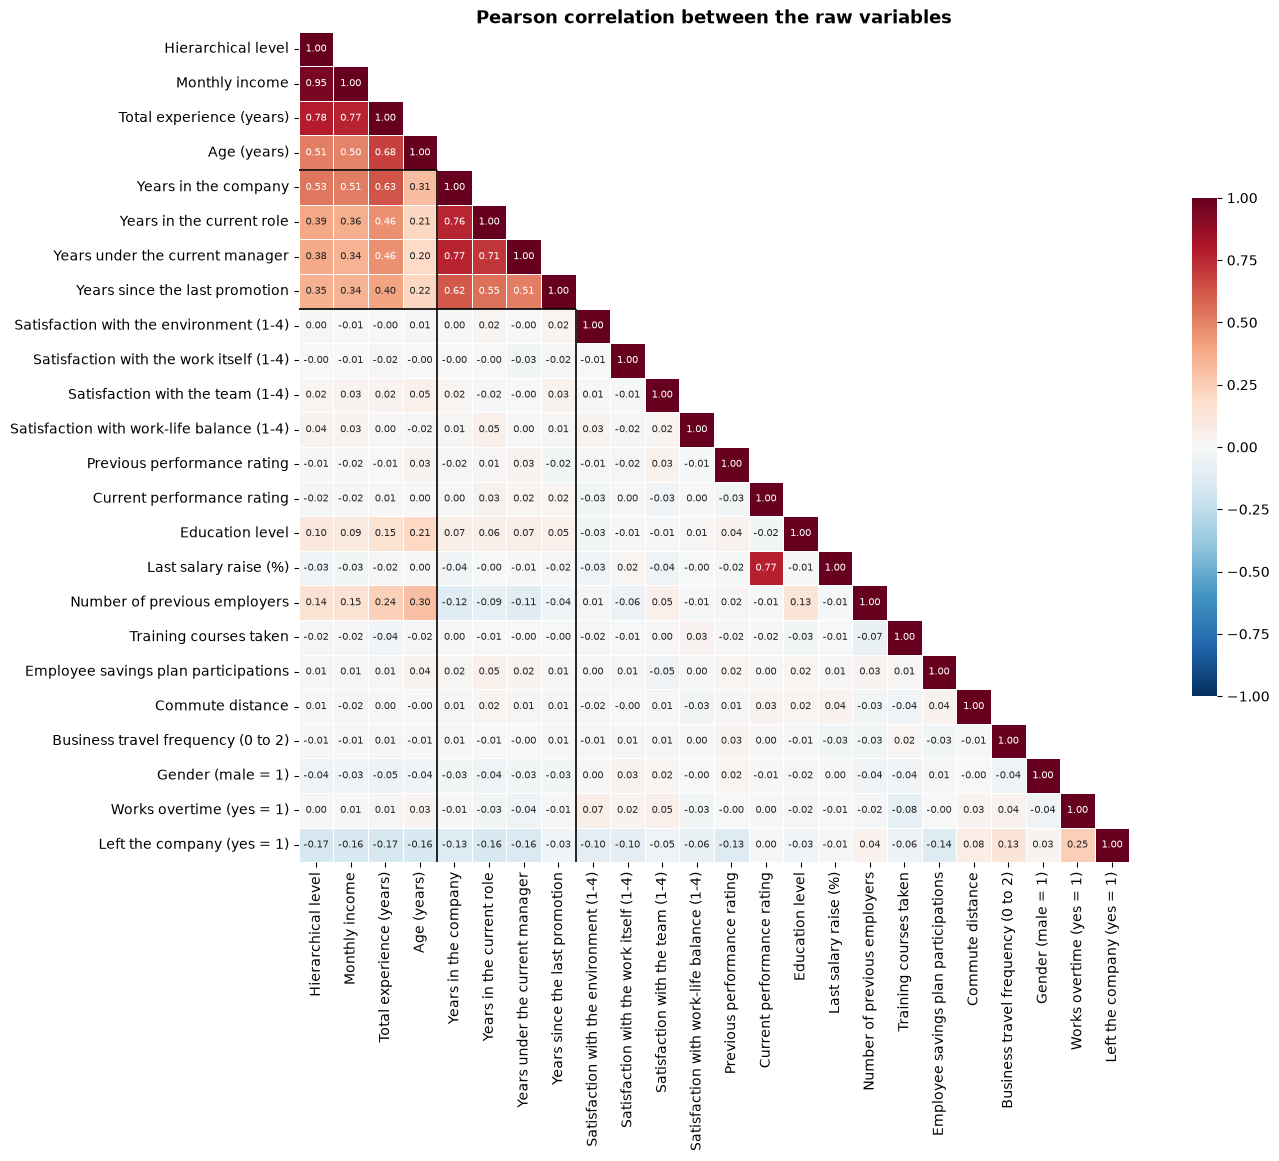

In [84]:
pearson = encoded.corr(method="pearson")
labels = [COLUMN_LABELS[col] for col in pearson.columns]

fig, ax = plt.subplots(figsize=(14, 11.5), layout="constrained")
sns.heatmap(
    pearson,
    mask=np.triu(np.ones_like(pearson, dtype=bool), k=1),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 7},
    linewidths=0.5,
    linecolor="white",
    square=True,
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={"shrink": 0.6},
    ax=ax,
)
for edge in (len(SENIORITY_BLOCK), len(grouped)):
    ax.hlines(edge, 0, edge, color="black", linewidth=1.2)
    ax.vlines(edge, edge, len(pearson), color="black", linewidth=1.2)
ax.grid(False)
ax.set_title("Pearson correlation between the raw variables")
plt.show()

In [85]:
REDUNDANCY_THRESHOLD = 0.7

spearman = encoded.corr(method="spearman")

first, second = np.triu_indices(len(pearson), k=1)
pairs = pd.DataFrame(
    {
        "Variable A": [COLUMN_LABELS[pearson.columns[i]] for i in first],
        "Variable B": [COLUMN_LABELS[pearson.columns[j]] for j in second],
        "Pearson": pearson.values[first, second],
        "Spearman": spearman.values[first, second],
    }
)
strong_pairs = (
    pairs[pairs["Pearson"].abs() >= REDUNDANCY_THRESHOLD]
    .sort_values("Pearson", key=abs, ascending=False)
    .reset_index(drop=True)
    .round(2)
)
display(strong_pairs)

satisfaction_columns = [
    col for col in numeric_columns if col.startswith("satisfaction_")
]
satisfaction_corr = pearson.loc[satisfaction_columns, satisfaction_columns].to_numpy()
print(
    "Largest correlation between two satisfaction scores:",
    round(float(np.abs(satisfaction_corr[np.triu_indices(4, k=1)]).max()), 2),
)

,Variable A,Variable B,Pearson,Spearman
0,Hierarchical level,Monthly income,0.95,0.92
1,Hierarchical level,Total experience (years),0.78,0.73
2,Current performance rating,Last salary raise (%),0.77,0.63
3,Monthly income,Total experience (years),0.77,0.71
4,Years in the company,Years under the current manager,0.77,0.84
5,Years in the company,Years in the current role,0.76,0.85
6,Years in the current role,Years under the current manager,0.71,0.72


Largest correlation between two satisfaction scores: 0.03


Two blocks stand out, seniority and time in the company, and the rating and the raise link unexpectedly at 0.77.

The target row shows weak links for satisfaction (-0.05 to -0.10) and business travel (0.13) despite the large gaps in leaving rate seen in the exploration, because Pearson only sees straight lines.

## 2. Feature engineering

We add five features that restate existing columns as counts and ratios, each computed from a single employee's row so that nothing leaks before the split.

- `satisfaction_lows` counts the satisfaction scores at 1, capped at 3 to mean 3 or more.
- `career_share_in_company` is the share of the total experience spent in the company, and takes 1 when the experience is 0.
- `role_share_of_tenure` is the share of the years in the company spent in the current role, and takes 1 when the tenure is 0.
- `promotion_wait_share` is the share of the years in the company spent since the last promotion, and takes 0 when the tenure is 0.
- `years_per_employer` is the total experience divided by the number of employers, the current one included.

In [86]:
SATISFACTION_COLUMNS = [
    col for col in employees.columns if col.startswith("satisfaction_employee_")
]
FEATURE_COLUMNS = [
    "satisfaction_lows",
    "career_share_in_company",
    "role_share_of_tenure",
    "promotion_wait_share",
    "years_per_employer",
]


def add_engineered_features(df):
    """Return the five engineered features of df, row by row.

    A ratio whose denominator is 0 takes a neutral value: 1 for the two shares of
    time already spent (a new hire has spent all of its tenure in the company and
    in the role), and 0 for the promotion wait.
    """
    experience = df["annees_experience_totale"]
    tenure = df["annees_dans_l_entreprise"]
    features = pd.DataFrame(index=df.index)
    features["satisfaction_lows"] = (
        (df[SATISFACTION_COLUMNS] == 1).sum(axis=1).clip(upper=3)
    )
    features["career_share_in_company"] = (tenure / experience).where(
        experience > 0, 1.0
    )
    features["role_share_of_tenure"] = (
        df["annees_dans_le_poste_actuel"] / tenure
    ).where(tenure > 0, 1.0)
    features["promotion_wait_share"] = (
        df["annees_depuis_la_derniere_promotion"] / tenure
    ).where(tenure > 0, 0.0)
    features["years_per_employer"] = experience / (
        df["nombre_experiences_precedentes"] + 1
    )
    return features[FEATURE_COLUMNS]


features = add_engineered_features(employees)
assert features.notna().all().all(), "a feature has a missing value"
assert np.isfinite(features).all().all(), "a feature has an infinite value"
assert set(FEATURE_COLUMNS) <= set(COLUMN_LABELS), "a feature has no label"

engineered = employees.join(features)
display(features.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
satisfaction_lows,1470.0,0.63,0.73,0.0,0.00,1.00,1.00,3.0
career_share_in_company,1470.0,0.69,0.32,0.0,0.43,0.80,1.00,1.0
role_share_of_tenure,1470.0,0.61,0.32,0.0,0.40,0.67,0.88,1.0
promotion_wait_share,1470.0,0.29,0.34,0.0,0.00,0.17,0.50,1.0
years_per_employer,1470.0,4.19,4.04,0.0,1.60,3.00,5.00,38.0


### Ratios

We compare the four ratios between leavers and stayers, to see whether they separate the two groups better than the raw durations.

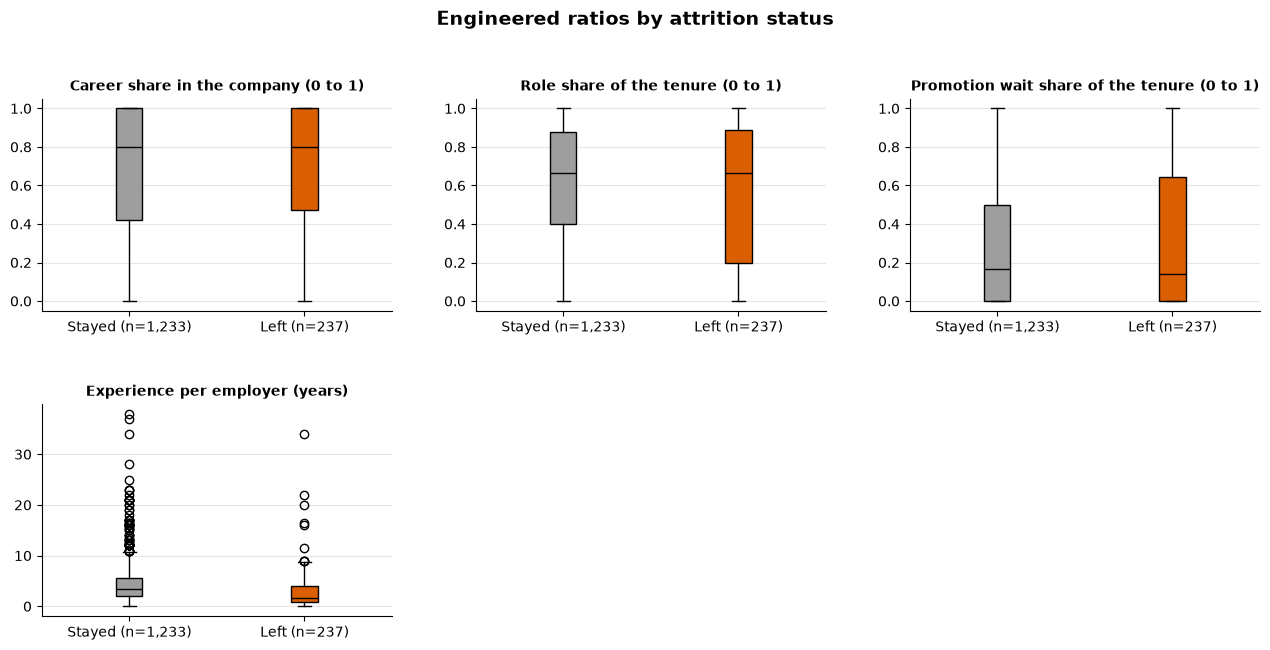

In [87]:
RATIO_COLUMNS = FEATURE_COLUMNS[1:]
plot_boxplots_by_target(
    engineered, RATIO_COLUMNS, "Engineered ratios by attrition status"
)

Leavers have a median of 1.6 years of experience per employer against 3.3 for stayers, while the three shares of tenure show almost no gap.

### Satisfaction scores at 1

We look at the leaving rate for each count of scores at 1, with the group sizes to avoid reading too much into small groups.

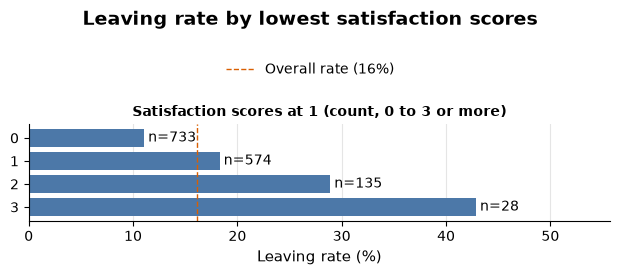

In [88]:
plot_leaving_rate_by_value(
    engineered,
    ["satisfaction_lows"],
    "Leaving rate by lowest satisfaction scores",
    n_cols=1,
    width=6.5,
)

The leaving rate climbs with each score at 1, from 11% with none to 29% with two and 43% with three or more.

## 3. Final redundancy check and decisions

We check the redundancies again with the five engineered features by listing every pair that reaches 0.7 in Pearson or in Spearman.

In [89]:
DROPS = {}


def correlated_pairs(df, threshold):
    """List the pairs of columns whose Pearson or Spearman correlation reaches the threshold."""
    pearson = df.corr(method="pearson")
    spearman = df.corr(method="spearman")
    first, second = np.triu_indices(len(pearson), k=1)
    pairs = pd.DataFrame(
        {
            "Variable A": [COLUMN_LABELS[pearson.columns[i]] for i in first],
            "Variable B": [COLUMN_LABELS[pearson.columns[j]] for j in second],
            "Pearson": pearson.values[first, second],
            "Spearman": spearman.values[first, second],
        }
    )
    keep = (pairs[["Pearson", "Spearman"]].abs() >= threshold).any(axis=1)
    return (
        pairs[keep]
        .sort_values("Pearson", key=abs, ascending=False)
        .reset_index(drop=True)
        .round(2)
    )


with_features = encoded.drop(columns=TARGET).join(features)
assert with_features.shape[1] == 28
display(correlated_pairs(with_features, REDUNDANCY_THRESHOLD))

,Variable A,Variable B,Pearson,Spearman
0,Hierarchical level,Monthly income,0.95,0.92
1,Hierarchical level,Total experience (years),0.78,0.73
2,Current performance rating,Last salary raise (%),0.77,0.63
3,Monthly income,Total experience (years),0.77,0.71
4,Years in the company,Years under the current manager,0.77,0.84
5,Years in the company,Years in the current role,0.76,0.85
6,Years in the current role,Years under the current manager,0.71,0.72
7,Years in the company,Experience per employer (years),0.70,0.67
8,Years since the last promotion,Promotion wait share of the tenure (0 to 1),0.63,0.91


Seven pairs repeat the first matrix and two are new, the years in the company with the years per employer (0.70) and the years since the last promotion with the promotion wait share (0.91 in Spearman).

We plot the seniority and time variables against each other, colored by status, to see whether the links hold over the whole range.

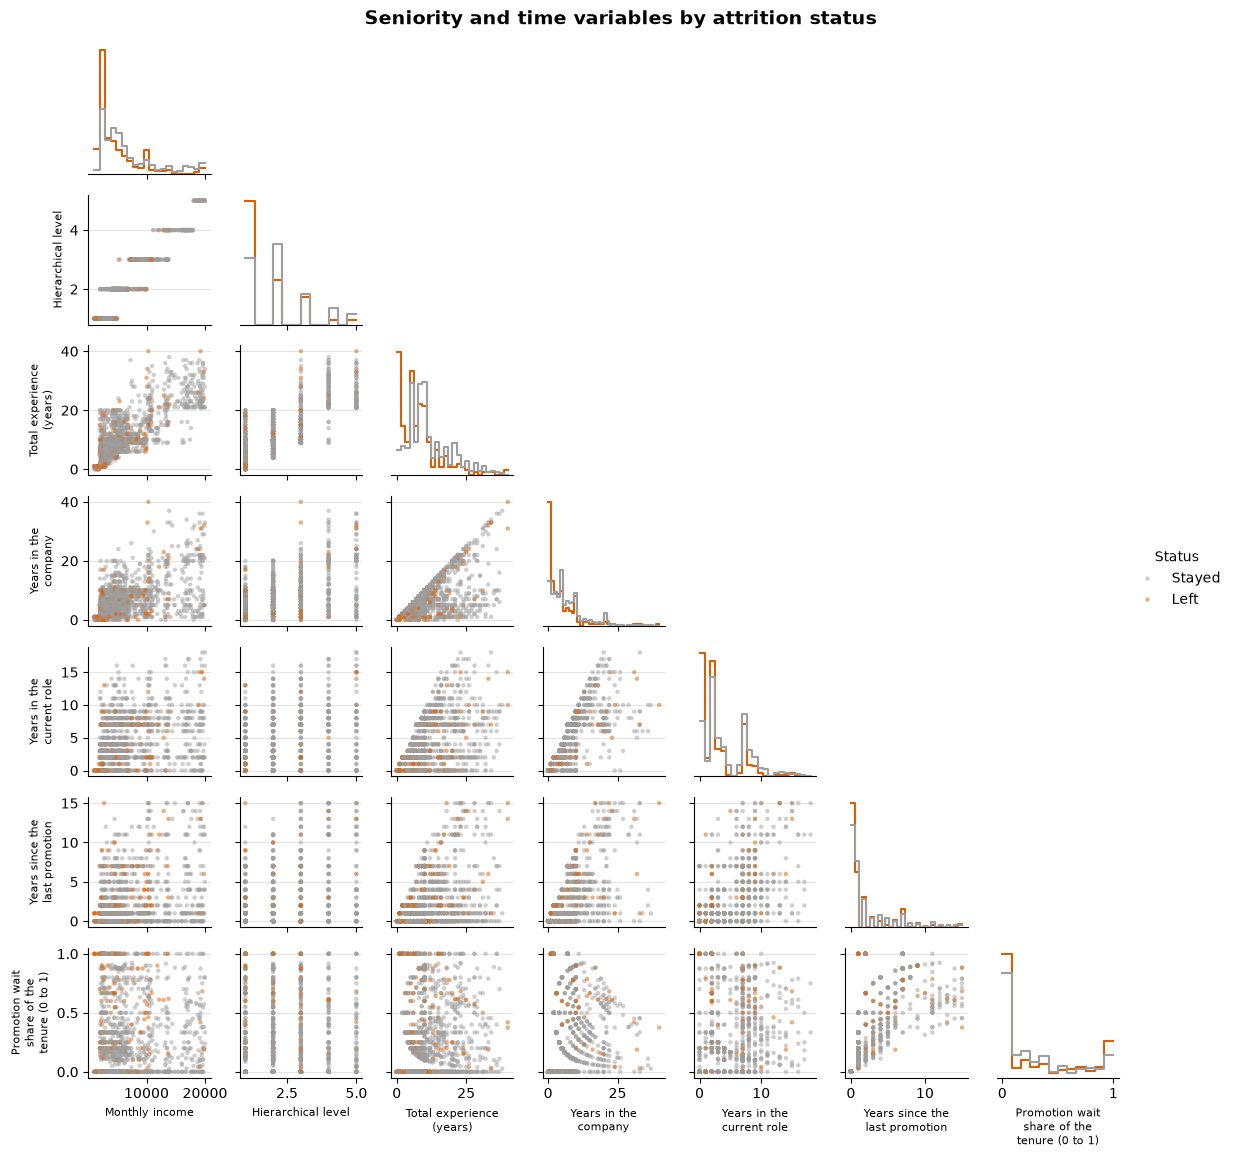

In [90]:
PAIRPLOT_COLUMNS = [
    "revenu_mensuel",
    "niveau_hierarchique_poste",
    "annees_experience_totale",
    "annees_dans_l_entreprise",
    "annees_dans_le_poste_actuel",
    "annees_depuis_la_derniere_promotion",
    "promotion_wait_share",
]

pairplot_data = engineered[PAIRPLOT_COLUMNS].assign(
    Status=employees[TARGET].map(TARGET_LABELS)
)
grid = sns.PairGrid(
    pairplot_data,
    hue="Status",
    hue_order=["Stayed", "Left"],
    palette=TARGET_COLORS,
    corner=True,
    diag_sharey=False,
    height=1.6,
)
grid.map_lower(sns.scatterplot, s=10, alpha=0.5, edgecolor="none")
grid.map_diag(
    sns.histplot, element="step", fill=False, stat="density", common_norm=False
)
grid.add_legend(title="Status")
for ax in grid.axes.flat:
    if ax is not None:
        ax.set_xlabel(
            textwrap.fill(COLUMN_LABELS.get(ax.get_xlabel(), ""), 18), fontsize=8
        )
        ax.set_ylabel(
            textwrap.fill(COLUMN_LABELS.get(ax.get_ylabel(), ""), 18), fontsize=8
        )
grid.figure.suptitle(
    "Seniority and time variables by attrition status",
    y=1.01,
    fontsize=14,
    fontweight="bold",
)
plt.show()

Monthly income rises in steps with the hierarchical level, and the promotion wait share follows the years since the last promotion along a fan of lines, one per tenure, which Spearman captures better than Pearson.

### Seniority

The hierarchical level reaches 0.95 with the monthly income, while income and total experience (0.77) measure pay and career length.

#### Decision

We remove the hierarchical level, since income is finer and a lever HR can act on, and keep the income and the experience.

In [91]:
DROPS["niveau_hierarchique_poste"] = "Same seniority as income (0.95)"

### Time in the company

The years in the current role can be rebuilt from the role share, and the years since the last promotion reach 0.91 in Spearman with the promotion wait share.

#### Decision

We remove the years in the current role and the years since the last promotion, and keep the years under the current manager and the years per employer, which add the stability of management and the pace of changing employers.

In [92]:
DROPS["annees_dans_le_poste_actuel"] = (
    "Rebuilt from the role share and the years in the company"
)
DROPS["annees_depuis_la_derniere_promotion"] = (
    "Kept as the promotion wait share (0.91 in Spearman)"
)

### Rating and raise

The current performance rating reaches 0.77 with the last salary raise, and it takes only two values.

#### Decision

We remove the current rating and keep the raise, which carries more detail.

In [93]:
DROPS["note_evaluation_actuelle"] = "Two values only, redundant with the raise (0.77)"

### Department and job title

The department could be a copy of the job title, so we count the employees and the leaving rate for each pair of job title and department.

In [94]:
role_department = (
    employees.groupby(["poste", "departement"])[TARGET]
    .agg(Employees="size", Leavers=lambda s: (s == "Oui").sum())
    .assign(
        **{"Leaving rate (%)": lambda t: (t["Leavers"] / t["Employees"] * 100).round()}
    )
    .astype(int)
    .rename_axis(index=["Job title", "Department"])
)
display(role_department)

departments_per_role = employees.groupby("poste")["departement"].nunique()
assert list(departments_per_role[departments_per_role > 1].index) == ["Senior Manager"]

Employees  Leavers  \
Job title               Department                                
Assistant de Direction  Consulting                 292       47   
Cadre Commercial        Commercial                 326       57   
Consultant              Consulting                 259       62   
Directeur Technique     Consulting                  80        2   
Manager                 Consulting                 131        9   
Représentant Commercial Commercial                  83       33   
Ressources Humaines     Ressources Humaines         52       12   
Senior Manager          Commercial                  37        2   
                        Consulting                  54        3   
                        Ressources Humaines         11        0   
Tech Lead               Consulting                 145       10   

                                             Leaving rate (%)  
Job title               Department                             
Assistant de Direction  Consulting                         16  
Cadre Commercial        Commercial                         17  
Consultant              Consulting                         24  
Directeur Technique     Consulting                          2  
Manager                 Consulting                          7  
Représentant Commercial Commercial                         40  
Ressources Humaines     Ressources Humaines                23  
Senior Manager          Commercial                          5  
                        Consulting                          6  
                        Ressources Humaines                 0  
Tech Lead               Consulting                          7

Each job title sits in a single department except Senior Manager, which spans three with leaving rates of 0 to 6%.

#### Decision

We remove the department, since it follows from the job title.

In [95]:
DROPS["departement"] = "Follows from the job title"

## 4. Inputs X and y

The registry holds the variables removed above and the reason for each.

In [96]:
display(
    pd.Series(DROPS, name="Reason")
    .rename(index=COLUMN_LABELS)
    .rename_axis("Variable")
    .to_frame()
)

,Reason
Variable,
Hierarchical level,Same seniority as income (0.95)
Years in the current role,Rebuilt from the role share and the years in the company
Years since the last promotion,Kept as the promotion wait share (0.91 in Spearman)
Current performance rating,"Two values only, redundant with the raise (0.77)"
Department,Follows from the job title


The function below drops them once and returns the inputs X and the target y, left unencoded because the encoding will sit in a pipeline after the split.

In [97]:
NOMINAL_COLUMNS = ["statut_marital", "poste", "domaine_etude"]


def build_inputs(df):
    """Return the model inputs X, not encoded yet, and the target y with 1 for the leavers."""
    X = df.drop(columns=[TARGET, *DROPS]).join(add_engineered_features(df))
    y = (df[TARGET] == "Oui").astype(int)
    return X, y


X, y = build_inputs(employees)

expected_columns = {
    col for col, kind in EMPLOYEE_KINDS.items() if kind != "target"
} - set(DROPS) | set(FEATURE_COLUMNS)
assert X.shape == (len(employees), 27)
assert set(X.columns) == expected_columns
assert set(NOMINAL_COLUMNS) <= set(X.columns)
assert X.notna().all().all()
assert X.index.equals(y.index)
assert set(y.unique()) == {0, 1}
assert y.sum() == 237

print(f"X: {X.shape[0]} rows x {X.shape[1]} columns, y: {int(y.sum())} leavers")
print(
    X.dtypes.map(lambda t: "number" if pd.api.types.is_numeric_dtype(t) else "text")
    .value_counts()
    .to_dict()
)

X: 1470 rows x 27 columns, y: 237 leavers
{'number': 21, 'text': 6}


## 5. Evaluation protocol

We hold out 20% of the employees as a test set, stratified on the target so that the leaving rate stays the same. The test set stays untouched until the final evaluation.

We split the remaining training set again, stratified 75/25, into a sub-train and a validation set. The validation set plays the role of the test set for the first models, and cross-validation will replace it later.

In [98]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_sub, X_val, y_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE
)

splits = {"Sub-train": y_sub, "Validation": y_val, "Test": y_test}
assert sum(len(part) for part in splits.values()) == len(y)
assert sum(int(part.sum()) for part in splits.values()) == y.sum()

display(
    pd.DataFrame(
        {
            "Employees": [len(part) for part in splits.values()],
            "Leavers": [int(part.sum()) for part in splits.values()],
            "Leaving rate (%)": [
                round(part.mean() * 100, 1) for part in splits.values()
            ],
        },
        index=pd.Index(splits, name="Set"),
    )
)
print(f"Chance level of the PR-AUC: {y.mean():.2f}")

,Employees,Leavers,Leaving rate (%)
Set,,,
Sub-train,882,143,16.2
Validation,294,47,16.0
Test,294,47,16.0


Chance level of the PR-AUC: 0.16


We compare the models on the PR-AUC, the area under the precision-recall curve, because the leavers are the minority class. A model that guesses at random scores the leaving rate of 0.16.

For the decision threshold, we will keep the one with the best precision under a minimum recall, chosen on out-of-fold probabilities.

## 6. Preprocessing

The function below builds a pipeline for a model family, so that the encoding and the scaling are learned on the training data only. The linear models get standardized numeric columns, and the tree models get them as they are.

The pipeline also takes optional extra features and columns to remove, which we will use to test feature variants.

In [99]:
BINARY_COLUMNS = [
    col for col, kind in EMPLOYEE_KINDS.items() if kind == "binary" and col in X
]
TRAVEL_COLUMN = "frequence_deplacement"
NUMERIC_COLUMNS = [col for col in X.columns if pd.api.types.is_numeric_dtype(X[col])]


def build_pipeline(model, family, extra_features=None, drop_columns=()):
    """Return the preprocessing and the model in one pipeline, for a "linear" or "tree" family.

    extra_features maps a new column name to the transformer that adds it before the
    preprocessing, and drop_columns lists the columns to leave out.
    """
    extra_features = extra_features or {}

    def keep(columns):
        return [col for col in columns if col not in drop_columns]

    numeric = StandardScaler() if family == "linear" else "passthrough"
    preprocessor = ColumnTransformer(
        [
            ("numeric", numeric, keep([*NUMERIC_COLUMNS, *extra_features])),
            (
                "travel",
                OrdinalEncoder(categories=[CATEGORY_ORDERS[TRAVEL_COLUMN]]),
                keep([TRAVEL_COLUMN]),
            ),
            ("binary", OneHotEncoder(drop="if_binary"), keep(BINARY_COLUMNS)),
            ("nominal", OneHotEncoder(handle_unknown="ignore"), keep(NOMINAL_COLUMNS)),
        ],
        verbose_feature_names_out=False,
    )
    feature_steps = list(extra_features.items())
    return Pipeline([*feature_steps, ("preprocessing", preprocessor), ("model", model)])

We check the output of both families on the sub-train, looking for missing values and for the expected number of columns.

In [100]:
n_nominal_columns = int(X_sub[NOMINAL_COLUMNS].nunique().sum())
expected_n_columns = len(NUMERIC_COLUMNS) + 1 + len(BINARY_COLUMNS) + n_nominal_columns

for family in ("linear", "tree"):
    preprocessor = build_pipeline(None, family)[:-1]
    encoded_sub = preprocessor.fit_transform(X_sub)
    assert not np.isnan(encoded_sub).any()
    assert encoded_sub.shape == (len(X_sub), expected_n_columns)
    print(
        f"{family}: {encoded_sub.shape[0]} rows x {encoded_sub.shape[1]} columns, "
        f"{expected_n_columns} expected"
    )

linear: 882 rows x 42 columns, 42 expected
tree: 882 rows x 42 columns, 42 expected


## 7. First models

We first set a business rule as a baseline, which flags an employee who works overtime or has at least two satisfaction scores at 1. The rule comes from the exploration of all employees, which can only favor it over the models.

We then train three models without class weights: a dummy that always predicts that the employee stays, a logistic regression, and a random forest. They set the reference that the next steps have to beat.

In [101]:
MODELS = {
    "Dummy": build_pipeline(DummyClassifier(strategy="most_frequent"), "tree"),
    "Logistic regression": build_pipeline(LogisticRegression(max_iter=1000), "linear"),
    "Random forest": build_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE), "tree"
    ),
}
for pipeline in MODELS.values():
    pipeline.fit(X_sub, y_sub)

EVALUATION_SETS = {"Sub-train": (X_sub, y_sub), "Validation": (X_val, y_val)}
RULE_NAME = "Business rule"


def apply_business_rule(df):
    """Flag with 1 the employees who work overtime or have at least two satisfaction scores at 1."""
    return (
        (df["heures_supplementaires"] == "Oui") | (df["satisfaction_lows"] >= 2)
    ).astype(int)


def evaluate(name, set_name, y_part, predicted, pr_auc):
    """Return one row of the metrics table."""
    return {
        "Model": name,
        "Set": set_name,
        "Accuracy": accuracy_score(y_part, predicted),
        "Precision": precision_score(y_part, predicted, zero_division=0),
        "Recall": recall_score(y_part, predicted),
        "F1": f1_score(y_part, predicted),
        "PR-AUC": pr_auc,
    }


probabilities = {}
rows = []
for name, pipeline in MODELS.items():
    for set_name, (X_part, y_part) in EVALUATION_SETS.items():
        scores = pipeline.predict_proba(X_part)[:, 1]
        probabilities[name, set_name] = scores
        rows.append(
            evaluate(
                name,
                set_name,
                y_part,
                pipeline.predict(X_part),
                average_precision_score(y_part, scores),
            )
        )
for set_name, (X_part, y_part) in EVALUATION_SETS.items():
    rows.append(
        evaluate(RULE_NAME, set_name, y_part, apply_business_rule(X_part), np.nan)
    )

metrics = pd.DataFrame(rows).set_index(["Model", "Set"])
order = ["Dummy", RULE_NAME, "Logistic regression", "Random forest"]
display(metrics.loc[order].round(2))

Accuracy  Precision  Recall    F1  PR-AUC
Model               Set                                                  
Dummy               Sub-train       0.84       0.00    0.00  0.00    0.16
                    Validation      0.84       0.00    0.00  0.00    0.16
Business rule       Sub-train       0.67       0.28    0.66  0.39     NaN
                    Validation      0.68       0.28    0.66  0.39     NaN
Logistic regression Sub-train       0.90       0.80    0.54  0.64    0.74
                    Validation      0.90       0.79    0.49  0.61    0.61
Random forest       Sub-train       1.00       1.00    1.00  1.00    1.00
                    Validation      0.87       0.78    0.30  0.43    0.55

We plot the confusion matrices on the validation set to see how many leavers each model misses.

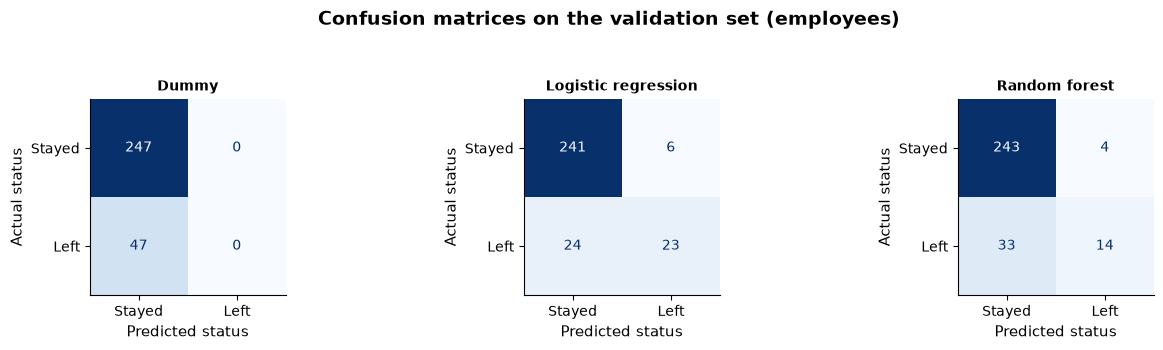

In [102]:
fig, axes = make_grid(len(MODELS), panel_height=3.8)
for ax, (name, pipeline) in zip(axes, MODELS.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        pipeline.predict(X_val),
        display_labels=["Stayed", "Left"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted status")
    ax.set_ylabel("Actual status")
    ax.grid(False)
fig.suptitle(
    "Confusion matrices on the validation set (employees)",
    fontsize=14,
    fontweight="bold",
)
plt.show()

The dummy reaches 0.84 accuracy without finding a single leaver, so accuracy cannot guide us and we rely on the PR-AUC, where the dummy sits at the 0.16 chance level.

The random forest memorizes the sub-train, with a PR-AUC of 1.00 against 0.55 on validation, while the logistic regression overfits much less.

Both models keep a precision near 0.8 on validation but miss most leavers, which class weights and the decision threshold will address.

The validation set holds only 47 leavers, so one leaver moves the recall by about 2 points, and the gap between the two models is not conclusive yet.

We draw the precision-recall curves of the two models on both sets, with the business rule as a single point, to compare them across all thresholds.

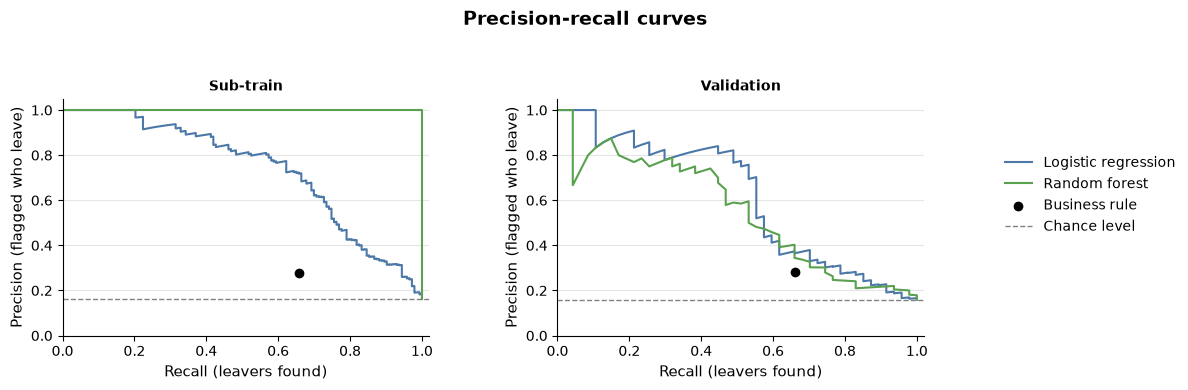

In [103]:
CURVE_COLORS = {"Logistic regression": RATE_BAR_COLOR, "Random forest": "#59a14f"}

fig, axes = make_grid(len(EVALUATION_SETS), panel_height=4.2, n_cols=2, width=12)
for ax, (set_name, (X_part, y_part)) in zip(axes, EVALUATION_SETS.items()):
    for name, color in CURVE_COLORS.items():
        precision, recall, _ = precision_recall_curve(
            y_part, probabilities[name, set_name]
        )
        ax.plot(recall, precision, color=color, label=name)
    rule_predicted = apply_business_rule(X_part)
    ax.scatter(
        recall_score(y_part, rule_predicted),
        precision_score(y_part, rule_predicted),
        color="black",
        zorder=3,
        label=RULE_NAME,
    )
    ax.axhline(
        y_part.mean(),
        color="gray",
        linestyle="--",
        linewidth=1,
        label="Chance level",
    )
    ax.set_title(set_name, fontsize=10)
    ax.set_xlabel("Recall (leavers found)")
    ax.set_ylabel("Precision (flagged who leave)")
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.05)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center")
fig.suptitle("Precision-recall curves", fontsize=14, fontweight="bold")
plt.show()

On validation, the business rule reaches a precision of 0.28, well above the chance level, while both models reach about 0.4 at the same recall, so they already beat it. The two curves stay close to each other, so the logistic regression is not clearly ahead of the forest.

We plot the predicted probabilities by actual status, to see how well each model separates the leavers from the stayers around the default 0.5 threshold.

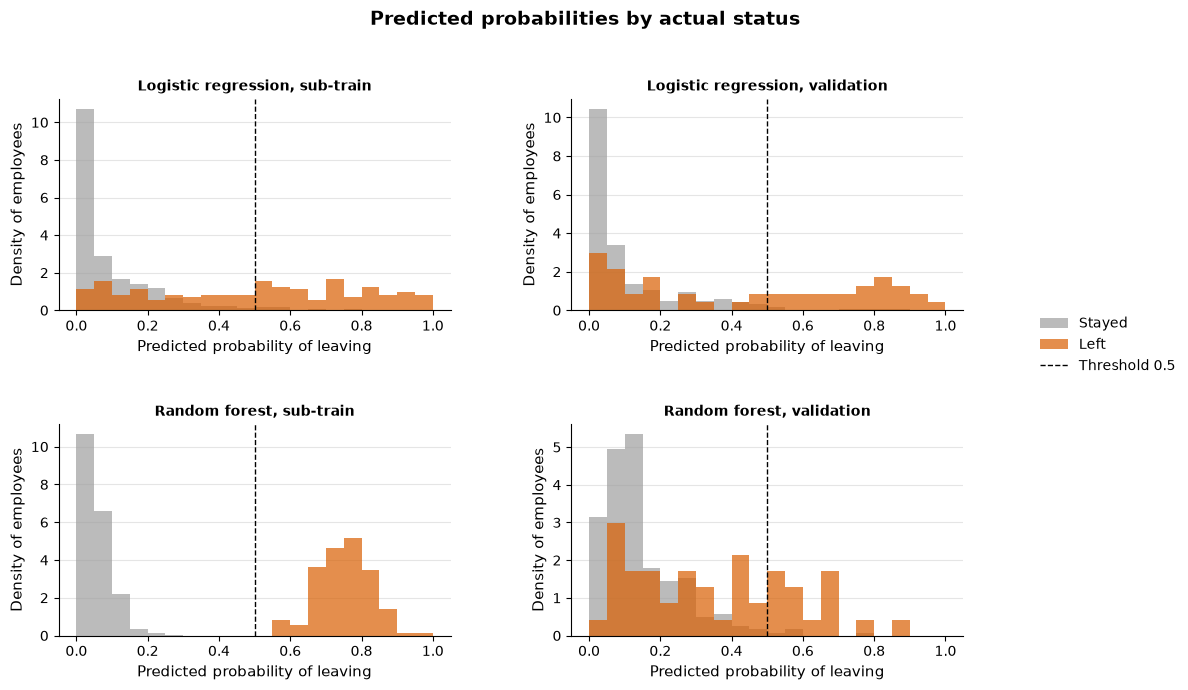

In [104]:
SCORED_MODELS = ["Logistic regression", "Random forest"]

fig, axes = make_grid(4, panel_height=3.6, n_cols=2, width=12)
panels = [(name, set_name) for name in SCORED_MODELS for set_name in EVALUATION_SETS]
bins = np.linspace(0, 1, 21)
for ax, (name, set_name) in zip(axes, panels):
    y_part = EVALUATION_SETS[set_name][1]
    scores = probabilities[name, set_name]
    for label, value in (("Stayed", 0), ("Left", 1)):
        ax.hist(
            scores[y_part.to_numpy() == value],
            bins=bins,
            density=True,
            alpha=0.7,
            color=TARGET_COLORS[label],
            label=label,
        )
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Threshold 0.5")
    ax.set_title(f"{name}, {set_name.lower()}", fontsize=10)
    ax.set_xlabel("Predicted probability of leaving")
    ax.set_ylabel("Density of employees")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center")
fig.suptitle(
    "Predicted probabilities by actual status",
    fontsize=14,
    fontweight="bold",
)
plt.show()

The logistic regression pushes most stayers close to 0 but spreads the leavers over the whole range, so many of them fall under the 0.5 threshold.

The random forest separates the two groups perfectly on the sub-train, but on validation most leavers sit below 0.5, next to the stayers.

A lower threshold would find more leavers but also flag more stayers, because the two groups overlap between 0.1 and 0.4, especially with the forest.

## 8. Cross-validation

From here on we work on the full training set, and the sub-train and validation sets of the previous section are not used any more. Every model is scored on the same five stratified folds, so the differences between models do not come from the splits.

The test set stays untouched until the tuned model is final, where it is evaluated once.

In [105]:
N_SPLITS = 5
CV = StratifiedKFold(N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

CV_MODELS = {
    "Dummy": build_pipeline(DummyClassifier(strategy="most_frequent"), "tree"),
    "Logistic regression": build_pipeline(LogisticRegression(max_iter=1000), "linear"),
    "Logistic regression, balanced": build_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced"), "linear"
    ),
    "Random forest": build_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE), "tree"
    ),
    "Random forest, balanced": build_pipeline(
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        "tree",
    ),
    "CatBoost, balanced": build_pipeline(
        CatBoostClassifier(
            auto_class_weights="Balanced",
            verbose=0,
            random_state=RANDOM_STATE,
            allow_writing_files=False,
        ),
        "tree",
    ),
}
SCORING = {
    "PR-AUC": "average_precision",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": "recall",
    "F1": "f1",
}

assert len(X_train) == 1176 and int(y_train.sum()) == 190
print(f"{N_SPLITS} folds of about {len(X_train) // N_SPLITS} employees each")

5 folds of about 235 employees each


We compare the models on the train and validation folds at the default threshold of 0.5, to see both the level of each metric and the gap that signals overfitting. The dummy and the business rule serve as references, the rule being scored on each validation fold.

In [106]:
def format_scores(values):
    """Return the mean and standard deviation of the fold scores as text."""
    return f"{np.mean(values):.2f} ± {np.std(values):.2f}"


def compare_models(models):
    """Cross-validate each model on X_train and return mean ± std per metric, with the business rule as a reference."""
    rows = {}
    for name, pipeline in models.items():
        results = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=CV,
            scoring=SCORING,
            return_train_score=True,
        )
        rows[name] = {
            (metric, part): format_scores(results[f"{key}_{metric}"])
            for metric in SCORING
            for part, key in (("Train", "train"), ("Validation", "test"))
        }

    rule_scores = {"Precision": [], "Recall": [], "F1": []}
    for _, val_index in CV.split(X_train, y_train):
        predicted = apply_business_rule(X_train.iloc[val_index])
        actual = y_train.iloc[val_index]
        rule_scores["Precision"].append(precision_score(actual, predicted))
        rule_scores["Recall"].append(recall_score(actual, predicted))
        rule_scores["F1"].append(f1_score(actual, predicted))
    rows[RULE_NAME] = {
        (metric, part): (
            format_scores(rule_scores[metric])
            if part == "Validation" and metric in rule_scores
            else "-"
        )
        for metric in SCORING
        for part in ("Train", "Validation")
    }
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    return table


cv_results = compare_models(CV_MODELS)
display(cv_results)

PR-AUC                 Precision  \
                                     Train   Validation        Train   
Dummy                          0.16 ± 0.00  0.16 ± 0.00  0.00 ± 0.00   
Logistic regression            0.73 ± 0.01  0.66 ± 0.05  0.83 ± 0.02   
Logistic regression, balanced  0.70 ± 0.01  0.63 ± 0.06  0.43 ± 0.02   
Random forest                  1.00 ± 0.00  0.57 ± 0.07  1.00 ± 0.00   
Random forest, balanced        1.00 ± 0.00  0.54 ± 0.06  0.99 ± 0.00   
CatBoost, balanced             1.00 ± 0.00  0.64 ± 0.05  0.99 ± 0.01   
Business rule                            -            -            -   

                                                 Recall               \
                                Validation        Train   Validation   
Dummy                          0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00   
Logistic regression            0.78 ± 0.07  0.50 ± 0.02  0.46 ± 0.13   
Logistic regression, balanced  0.39 ± 0.02  0.81 ± 0.01  0.74 ± 0.06   
Random forest                  0.81 ± 0.12  1.00 ± 0.00  0.22 ± 0.10   
Random forest, balanced        0.63 ± 0.09  1.00 ± 0.00  0.35 ± 0.09   
CatBoost, balanced             0.71 ± 0.05  1.00 ± 0.00  0.51 ± 0.11   
Business rule                  0.28 ± 0.03            -  0.66 ± 0.06   

                                        F1               
                                     Train   Validation  
Dummy                          0.00 ± 0.00  0.00 ± 0.00  
Logistic regression            0.63 ± 0.02  0.57 ± 0.10  
Logistic regression, balanced  0.56 ± 0.01  0.51 ± 0.02  
Random forest                  1.00 ± 0.00  0.33 ± 0.12  
Random forest, balanced        1.00 ± 0.00  0.44 ± 0.09  
CatBoost, balanced             0.99 ± 0.00  0.58 ± 0.09  
Business rule                            -  0.39 ± 0.03

The random forest and CatBoost memorize the training folds, with a PR-AUC of 1.00, while the logistic regression only drops from 0.73 to 0.66.

At the default threshold, class weights trade precision for recall, and the forest finds few leavers with or without them.

On validation PR-AUC, the logistic regression, its balanced version and CatBoost stay within 0.63 to 0.66, closer than the spread between folds of 0.05 to 0.06, and the two forests are lower.

## 9. Out-of-fold probabilities

Each employee is scored by a model that never saw them, which gives one probability per employee of the training set. We use these probabilities to draw the precision-recall curves and to choose the thresholds, always on the same 1,176 employees.

In [107]:
CURVE_MODELS = [name for name in CV_MODELS if name != "Dummy"]
MODEL_COLORS = dict(
    zip(
        CURVE_MODELS,
        ["#4c78a8", "#17becf", "#59a14f", "#9467bd", "#8c564b"],
    )
)

oof_probabilities = {
    name: cross_val_predict(
        CV_MODELS[name], X_train, y_train, cv=CV, method="predict_proba"
    )[:, 1]
    for name in CURVE_MODELS
}

## 10. Decision threshold

We need the model to find most of the leavers, so we set a minimum recall of 0.75 and keep, for each model, the threshold with the best precision among those that reach it.

In [108]:
MIN_RECALL = 0.75


def best_threshold(y_true, scores, min_recall=MIN_RECALL):
    """Return the threshold with the best precision among those with a recall of at least min_recall."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    candidates = np.flatnonzero(recall[:-1] >= min_recall)
    return thresholds[candidates[np.argmax(precision[candidates])]]


rows = {}
for name in CURVE_MODELS:
    threshold = best_threshold(y_train, oof_probabilities[name])
    flagged = oof_probabilities[name] >= threshold
    fold_precisions = [
        precision_score(y_train.iloc[val], flagged[val], zero_division=0)
        for _, val in CV.split(X_train, y_train)
    ]
    rows[name] = {
        "Threshold": threshold,
        "Precision": precision_score(y_train, flagged),
        "Precision per fold": format_scores(fold_precisions),
        "Recall": recall_score(y_train, flagged),
        "Flagged employees": int(flagged.sum()),
    }
chosen_thresholds = pd.DataFrame.from_dict(rows, orient="index")
assert (chosen_thresholds["Recall"] >= MIN_RECALL).all()
display(chosen_thresholds.round(2))
print(f"Business rule: {int(apply_business_rule(X_train).sum())} flagged employees")

,Threshold,Precision,Precision per fold,Recall,Flagged employees
Logistic regression,0.17,0.40,0.40 ± 0.03,0.76,359
"Logistic regression, balanced",0.49,0.40,0.40 ± 0.02,0.75,362
Random forest,0.18,0.35,0.36 ± 0.02,0.75,404
"Random forest, balanced",0.28,0.35,0.35 ± 0.03,0.75,412
"CatBoost, balanced",0.20,0.36,0.36 ± 0.02,0.75,401


Business rule: 450 flagged employees


At the minimum recall, class weights do not change the precision of the logistic regression or the forest, they only move the threshold, from 0.17 to 0.49 for the logistic regression.

The logistic regression finds more leavers than the business rule with fewer flagged employees, 359 against 450, and a precision of 0.40 against 0.28.

The precision varies by only 0.02 to 0.03 between folds, so the gap of both kept models over the rule is well beyond the noise, while the gap between the logistic regression and the forests separates them only weakly.

We draw the curves of the five models with the business rule as a single point and the chosen threshold of each model, to see where the minimum recall places them.

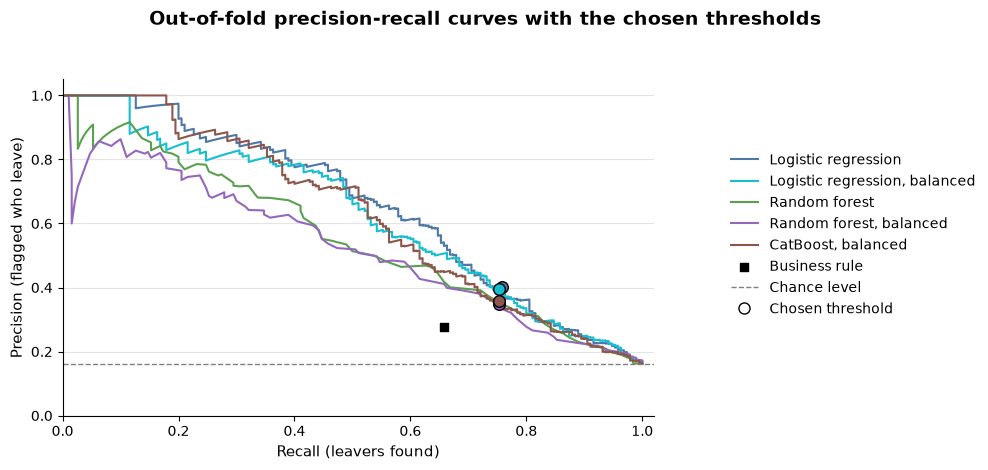

In [109]:
def plot_oof_curves(title, chosen=None, scores=oof_probabilities, colors=MODEL_COLORS):
    """Draw the out-of-fold precision-recall curves, with the chosen threshold of each model when given."""
    fig, axes = make_grid(1, panel_height=5, n_cols=1, width=10)
    ax = axes[0]
    for name, color in colors.items():
        precision, recall, _ = precision_recall_curve(y_train, scores[name])
        ax.plot(recall, precision, color=color, label=name)
        if chosen is not None:
            ax.scatter(
                chosen.loc[name, "Recall"],
                chosen.loc[name, "Precision"],
                s=70,
                color=color,
                edgecolor="black",
                zorder=4,
            )
    rule_predicted = apply_business_rule(X_train)
    ax.scatter(
        recall_score(y_train, rule_predicted),
        precision_score(y_train, rule_predicted),
        color="black",
        marker="s",
        zorder=3,
        label=RULE_NAME,
    )
    ax.axhline(
        y_train.mean(),
        color="gray",
        linestyle="--",
        linewidth=1,
        label="Chance level",
    )
    handles, labels = ax.get_legend_handles_labels()
    if chosen is not None:
        handles.append(
            plt.Line2D(
                [],
                [],
                marker="o",
                linestyle="",
                color="white",
                markeredgecolor="black",
                markersize=8,
            )
        )
        labels.append("Chosen threshold")
    ax.set_xlabel("Recall (leavers found)")
    ax.set_ylabel("Precision (flagged who leave)")
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.05)
    fig.legend(handles, labels, loc="outside right center")
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.show()


plot_oof_curves(
    "Out-of-fold precision-recall curves with the chosen thresholds", chosen_thresholds
)

We plot the out-of-fold confusion matrices at the chosen thresholds, to see how many stayers each model flags to reach the minimum recall.

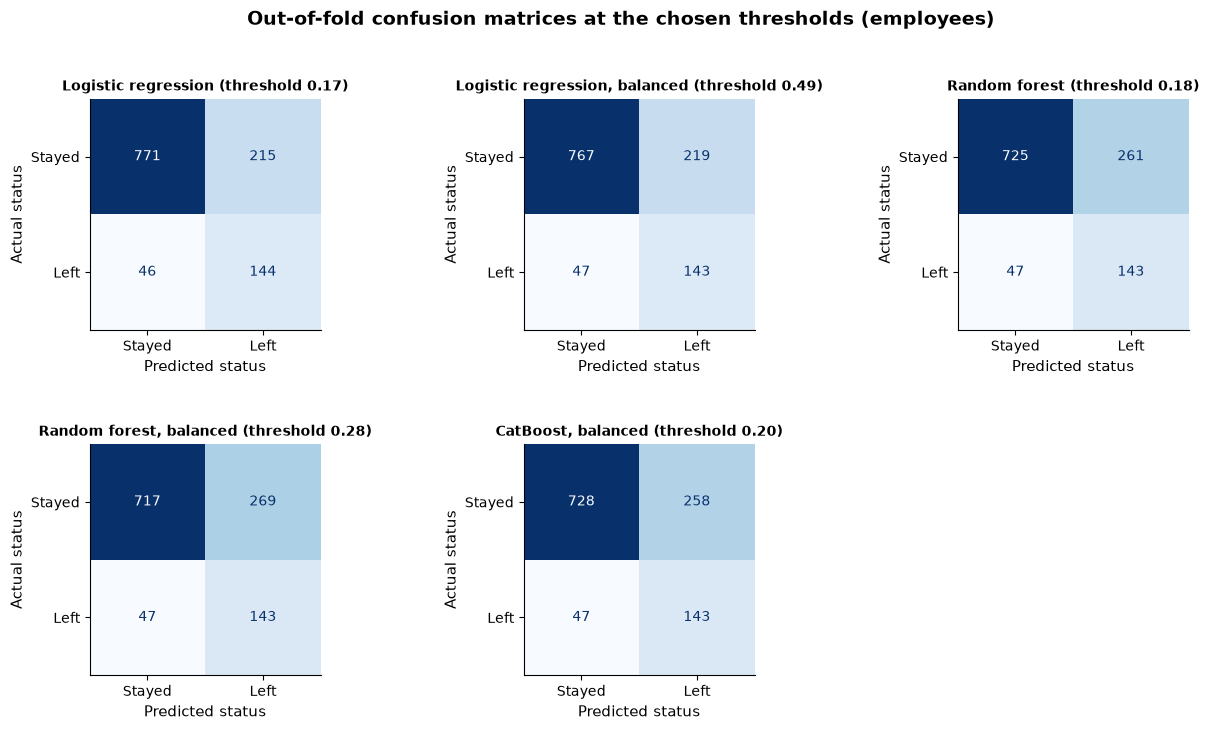

In [110]:
fig, axes = make_grid(len(CURVE_MODELS), panel_height=3.8)
for ax, name in zip(axes, CURVE_MODELS):
    threshold = chosen_thresholds.loc[name, "Threshold"]
    ConfusionMatrixDisplay.from_predictions(
        y_train,
        oof_probabilities[name] >= threshold,
        display_labels=["Stayed", "Left"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{name} (threshold {threshold:.2f})", fontsize=10)
    ax.set_xlabel("Predicted status")
    ax.set_ylabel("Actual status")
    ax.grid(False)
fig.suptitle(
    "Out-of-fold confusion matrices at the chosen thresholds (employees)",
    fontsize=14,
    fontweight="bold",
)
plt.show()

To find three leavers out of four, every model flags more stayers than leavers, about 1.5 stayers per leaver found for the logistic regression.

#### Decisions

* We keep the logistic regression and the balanced CatBoost for tuning, and drop the random forest, which stays below them with or without class weights.
* The logistic regression stays without class weights, since they only move its threshold once it is chosen on the precision-recall curve.
* We do not use resampling, since both kept models beat the business rule at the minimum recall by more than the spread between folds.

## 11. Feature engineering

We test three candidates on the two models kept for tuning, the logistic regression and the balanced CatBoost, with the same folds as before.

- `income_vs_role_median` is the monthly income divided by the median income of the job title. A transformer inside the pipeline learns the medians on the training folds only, and uses the overall median for a job title it has not seen.
- `business_rule_flag` is the business rule as a 0/1 feature.
- The third candidate removes the years under the current manager, which we kept for now despite its 0.77 correlation with the years in the company.

We test each candidate alone against the baseline. A candidate is kept if it improves the PR-AUC on at least four folds out of five for one model, without lowering the other on average.

The two candidates that add a column are transformers placed before the preprocessing, so that anything they learn comes from the training folds only.

In [111]:
class IncomeVsRoleMedian(BaseEstimator, TransformerMixin):
    """Add the monthly income divided by the median income of the job title, learned on the fitted rows."""

    def fit(self, X, y=None):
        self.medians_ = X.groupby("poste")["revenu_mensuel"].median()
        self.global_median_ = X["revenu_mensuel"].median()
        return self

    def transform(self, X):
        medians = X["poste"].map(self.medians_).fillna(self.global_median_)
        return X.assign(income_vs_role_median=X["revenu_mensuel"] / medians)


class BusinessRuleFlag(BaseEstimator, TransformerMixin):
    """Add the business rule as a 0/1 feature, computed row by row."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.assign(business_rule_flag=apply_business_rule(X))

We compare leavers and stayers on the income ratio over the training set, as we did for the other ratios.

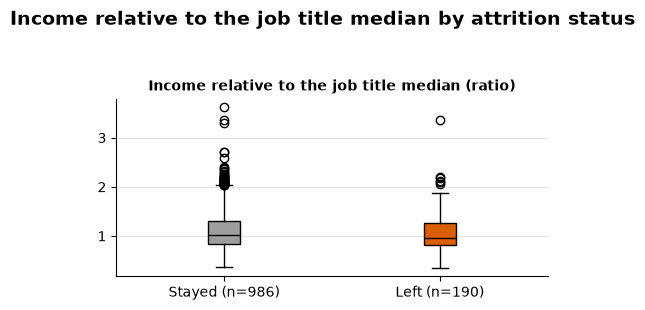

In [112]:
income_ratio = (
    IncomeVsRoleMedian().fit(X_train).transform(X_train)["income_vs_role_median"]
)
candidate = pd.DataFrame(
    {"income_vs_role_median": income_ratio, TARGET: y_train.map({1: "Oui", 0: "Non"})}
)
plot_boxplots_by_target(
    candidate,
    ["income_vs_role_median"],
    "Income relative to the job title median by attrition status",
    n_cols=1,
    width=5,
)

The two groups have almost the same distribution, with a median close to 1 and a similar spread, so the ratio does not separate leavers from stayers on its own.

Since every variant shares the same folds, we compare each one with the baseline fold by fold, which removes the difficulty of each fold. We report the PR-AUC, the mean difference and the number of folds where the variant is above the baseline.

In [113]:
BASELINE = "Baseline"
VARIANTS = {
    BASELINE: {},
    "Income vs role median": {
        "extra_features": {"income_vs_role_median": IncomeVsRoleMedian()}
    },
    "Business rule flag": {
        "extra_features": {"business_rule_flag": BusinessRuleFlag()}
    },
    "Without years under the manager": {
        "drop_columns": ("annees_sous_responsable_actuel",)
    },
}
KEPT_FAMILIES = {"Logistic regression": "linear", "CatBoost, balanced": "tree"}


def compare_variants(variants):
    """Return, for each kept model and variant, the PR-AUC over the folds and its fold-by-fold difference with the baseline."""
    rows = {}
    for model_name, family in KEPT_FAMILIES.items():
        model = CV_MODELS[model_name].named_steps["model"]
        scores = {
            variant: cross_validate(
                build_pipeline(model, family, **options),
                X_train,
                y_train,
                cv=CV,
                scoring="average_precision",
            )["test_score"]
            for variant, options in variants.items()
        }
        for variant, fold_scores in scores.items():
            difference = fold_scores - scores[BASELINE]
            is_baseline = variant == BASELINE
            rows[model_name, variant] = {
                "PR-AUC": format_scores(fold_scores),
                "Mean difference": "-" if is_baseline else f"{difference.mean():+.3f}",
                "Folds above baseline": (
                    "-"
                    if is_baseline
                    else f"{int((difference > 0).sum())} of {N_SPLITS}"
                ),
            }
    return pd.DataFrame(
        list(rows.values()),
        index=pd.MultiIndex.from_tuples(rows, names=["Model", "Variant"]),
    )


display(compare_variants(VARIANTS))

PR-AUC  \
Model               Variant                                        
Logistic regression Baseline                         0.66 ± 0.05   
                    Income vs role median            0.67 ± 0.05   
                    Business rule flag               0.66 ± 0.05   
                    Without years under the manager  0.66 ± 0.04   
CatBoost, balanced  Baseline                         0.64 ± 0.05   
                    Income vs role median            0.64 ± 0.05   
                    Business rule flag               0.64 ± 0.05   
                    Without years under the manager  0.63 ± 0.05   

                                                    Mean difference  \
Model               Variant                                           
Logistic regression Baseline                                      -   
                    Income vs role median                    +0.003   
                    Business rule flag                       -0.004   
                    Without years under the manager          -0.001   
CatBoost, balanced  Baseline                                      -   
                    Income vs role median                    +0.008   
                    Business rule flag                       +0.008   
                    Without years under the manager          -0.002   

                                                    Folds above baseline  
Model               Variant                                               
Logistic regression Baseline                                           -  
                    Income vs role median                         4 of 5  
                    Business rule flag                            2 of 5  
                    Without years under the manager               1 of 5  
CatBoost, balanced  Baseline                                           -  
                    Income vs role median                         4 of 5  
                    Business rule flag                            4 of 5  
                    Without years under the manager               2 of 5

Income relative to the job title median is above the baseline on four folds out of five for both models, but its mean gains stay below 0.01, far within the spread of 0.05 between folds. The models already see the monthly income and the job title, so the ratio mostly restates what they can combine on their own.

The business rule flag helps CatBoost slightly but lowers the logistic regression on average, so it does not meet the rule.

Removing the years under the manager lowers both models on average, so it does not meet the rule either.

#### Decisions

* We do not add the income relative to the job title median: it meets the rule, but its gain stays far within the spread between folds, and a simpler pipeline is worth more than it.
* We do not add the business rule flag, which lowers the logistic regression on average.
* We keep the years under the current manager, since removing them lowers both models.

## 12. Hyperparameter search

CatBoost is the final model, since the project asks for a tuned non-linear model, and the tuned logistic regression stays as the benchmark. Both searches use the shared folds and score the PR-AUC.

We try 50 random combinations for CatBoost and a full grid of 22 combinations for the logistic regression. To measure how sensitive each model is to its hyperparameters, we then compare the default model, the median of the tried combinations and the best one.

In [114]:
catboost_search = RandomizedSearchCV(
    build_pipeline(
        CatBoostClassifier(
            verbose=0, random_state=RANDOM_STATE, allow_writing_files=False
        ),
        "tree",
    ),
    param_distributions={
        "model__depth": randint(3, 9),
        "model__learning_rate": loguniform(0.01, 0.3),
        "model__iterations": randint(200, 1001),
        "model__l2_leaf_reg": loguniform(1, 30),
        "model__auto_class_weights": ["Balanced", "SqrtBalanced"],
    },
    n_iter=50,
    cv=CV,
    scoring="average_precision",
    return_train_score=True,
    random_state=RANDOM_STATE,
    # CatBoost already uses all the cores inside each fit
    n_jobs=1,
)
catboost_search.fit(X_train, y_train);

In [115]:
logistic_search = GridSearchCV(
    build_pipeline(
        LogisticRegression(solver="liblinear", max_iter=1000),
        "linear",
    ),
    param_grid={
        "model__C": np.logspace(-3, 2, 11),
        "model__l1_ratio": [0, 1],
    },
    cv=CV,
    scoring="average_precision",
    return_train_score=True,
)
logistic_search.fit(X_train, y_train);

We print the best parameters of each search and the PR-AUC of the default model, the median combination and the best one. The default models are the ones of the cross-validation, the CatBoost being the balanced version.

In [116]:
SEARCHES = {
    "CatBoost": (catboost_search, "CatBoost, balanced"),
    "Logistic regression": (logistic_search, "Logistic regression"),
}


def summarize_search(search, default_name):
    """Return the PR-AUC of the default model, of the median combination and of the best one."""
    results = pd.DataFrame(search.cv_results_)
    best = results.loc[search.best_index_]
    rows = {
        "Default": {},
        f"Median of {len(results)} combinations": {},
        "Best combination": {},
    }
    for part, key in (("Train", "train"), ("Validation", "test")):
        mean, std = f"mean_{key}_score", f"std_{key}_score"
        median_row, best_row = list(rows)[1:]
        rows["Default"][part] = cv_results.loc[default_name, ("PR-AUC", part)]
        rows[median_row][part] = (
            f"{results[mean].median():.2f} ± {results[std].median():.2f}"
        )
        rows[best_row][part] = f"{best[mean]:.2f} ± {best[std]:.2f}"
    return pd.DataFrame(rows).T


for name, (search, _) in SEARCHES.items():
    print(f"{name}: {search.best_params_}")
display(
    pd.concat(
        {
            name: summarize_search(search, default)
            for name, (search, default) in SEARCHES.items()
        }
    )
)

CatBoost: {'model__auto_class_weights': 'SqrtBalanced', 'model__depth': 4, 'model__iterations': 469, 'model__l2_leaf_reg': np.float64(11.865032251194263), 'model__learning_rate': np.float64(0.030362694519014993)}
Logistic regression: {'model__C': np.float64(1.0), 'model__l1_ratio': 0}


Train   Validation
CatBoost            Default                    1.00 ± 0.00  0.64 ± 0.05
                    Median of 50 combinations  1.00 ± 0.00  0.63 ± 0.05
                    Best combination           0.98 ± 0.00  0.66 ± 0.06
Logistic regression Default                    0.73 ± 0.01  0.66 ± 0.05
                    Median of 22 combinations  0.72 ± 0.01  0.65 ± 0.05
                    Best combination           0.73 ± 0.01  0.66 ± 0.05

The best CatBoost uses shallow trees of depth 4, a slow learning rate of 0.03 and a strong regularization of 12, and it memorizes the training folds less, with a train PR-AUC of 0.98 against 1.00 for the default.

The default, median and best combinations stay within 0.03 on validation, less than the standard deviation of 0.05, so tuning brings little. The best of the 50 trials is also slightly optimistic, since it is chosen on the folds that score it.

The best logistic regression is its default setting, a C of 1 with an L2 penalty, so its grid brings nothing.

We plot the validation PR-AUC of the 50 CatBoost trials against the depth of the trees, to see which depths the good combinations share.

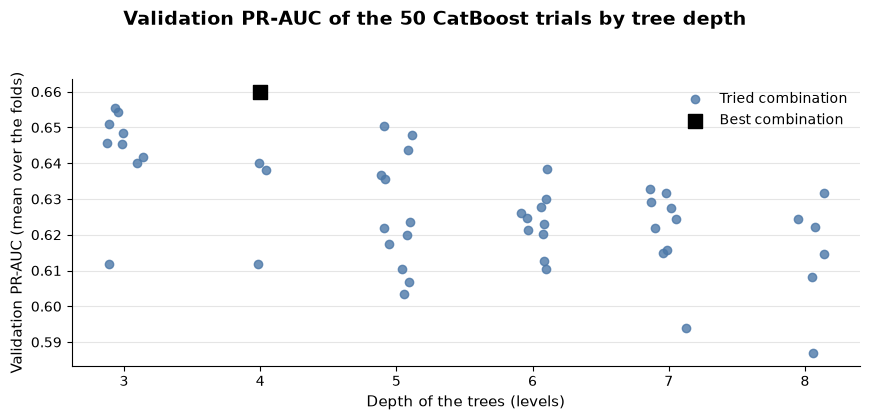

In [117]:
results = pd.DataFrame(catboost_search.cv_results_)
depth = results["param_model__depth"].astype(int)
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.15, 0.15, len(results))

fig, axes = make_grid(1, panel_height=4.5, n_cols=1, width=9)
ax = axes[0]
ax.scatter(
    depth + jitter,
    results["mean_test_score"],
    color=RATE_BAR_COLOR,
    alpha=0.8,
    label="Tried combination",
)
best_index = catboost_search.best_index_
ax.scatter(
    depth[best_index],
    results.loc[best_index, "mean_test_score"],
    s=90,
    color="black",
    marker="s",
    zorder=3,
    label="Best combination",
)
ax.set_xticks(sorted(depth.unique()))
ax.set_xlabel("Depth of the trees (levels)")
ax.set_ylabel("Validation PR-AUC (mean over the folds)")
ax.legend()
fig.suptitle(
    f"Validation PR-AUC of the {len(results)} CatBoost trials by tree depth",
    fontsize=14,
    fontweight="bold",
)
plt.show()

The best trials sit at depths 3 to 5, and no trial at depths 6 to 8 passes 0.64, so deeper trees score lower.

The signal therefore seems to involve few interactions between features, which is consistent with the logistic regression doing as well as CatBoost.

## 13. Tuned models and threshold

We score each employee of the training set with the two tuned models, through the same folds as before, so that each probability comes from a model that never saw the employee.

In [118]:
TUNED_MODELS = {
    "Logistic regression, tuned": logistic_search.best_estimator_,
    "CatBoost, tuned": catboost_search.best_estimator_,
}
TUNED_COLORS = dict(
    zip(
        TUNED_MODELS,
        [MODEL_COLORS["Logistic regression"], MODEL_COLORS["CatBoost, balanced"]],
    )
)

tuned_probabilities = {
    name: cross_val_predict(model, X_train, y_train, cv=CV, method="predict_proba")[
        :, 1
    ]
    for name, model in TUNED_MODELS.items()
}

We choose the threshold of each tuned model at the minimum recall of 0.75, and compare the flagged employees with the business rule.

In [119]:
rows = {}
for name, scores in tuned_probabilities.items():
    threshold = best_threshold(y_train, scores)
    flagged = scores >= threshold
    fold_precisions = [
        precision_score(y_train.iloc[val], flagged[val], zero_division=0)
        for _, val in CV.split(X_train, y_train)
    ]
    rows[name] = {
        "Threshold": threshold,
        "Precision": precision_score(y_train, flagged),
        "Precision per fold": format_scores(fold_precisions),
        "Recall": recall_score(y_train, flagged),
        "Flagged employees": int(flagged.sum()),
    }
tuned_thresholds = pd.DataFrame.from_dict(rows, orient="index")
assert (tuned_thresholds["Recall"] >= MIN_RECALL).all()
display(tuned_thresholds.round(2))
print(f"Business rule: {int(apply_business_rule(X_train).sum())} flagged employees")

,Threshold,Precision,Precision per fold,Recall,Flagged employees
"Logistic regression, tuned",0.17,0.39,0.40 ± 0.03,0.75,363
"CatBoost, tuned",0.22,0.39,0.40 ± 0.03,0.75,363


Business rule: 450 flagged employees


At the minimum recall, the two tuned models flag the same number of employees, 363, with the same precision of 0.39, so tuning does not separate them.

Both flag fewer employees than the business rule, 363 against 450, with a precision well above its 0.28, and the precision varies by only 0.03 between folds.

We count the employees flagged by both tuned models at their chosen thresholds, and the leavers that only one of them finds.

In [120]:
tuned_flags = {
    name: tuned_probabilities[name] >= tuned_thresholds.loc[name, "Threshold"]
    for name in TUNED_MODELS
}
by_catboost = tuned_flags["CatBoost, tuned"]
by_logistic = tuned_flags["Logistic regression, tuned"]
is_leaver = y_train.to_numpy() == 1

print(f"Flagged by both models: {int((by_catboost & by_logistic).sum())}")
print(f"Flagged by CatBoost only: {int((by_catboost & ~by_logistic).sum())}")
print(
    f"Flagged by the logistic regression only: {int((~by_catboost & by_logistic).sum())}"
)
print(
    f"Leavers found by both models: {int((by_catboost & by_logistic & is_leaver).sum())}"
)
print(
    f"Leavers found by CatBoost only: {int((by_catboost & ~by_logistic & is_leaver).sum())}"
)
print(
    f"Leavers found by the logistic regression only: {int((~by_catboost & by_logistic & is_leaver).sum())}"
)

Flagged by both models: 283
Flagged by CatBoost only: 80
Flagged by the logistic regression only: 80
Leavers found by both models: 134
Leavers found by CatBoost only: 9
Leavers found by the logistic regression only: 9


The two models share 283 of their 363 flagged employees and each finds 9 leavers the other misses, so they agree on 134 of the 143 leavers found and are largely interchangeable.

We draw the out-of-fold curves of the two tuned models with the business rule as a single point and the chosen threshold of each model.

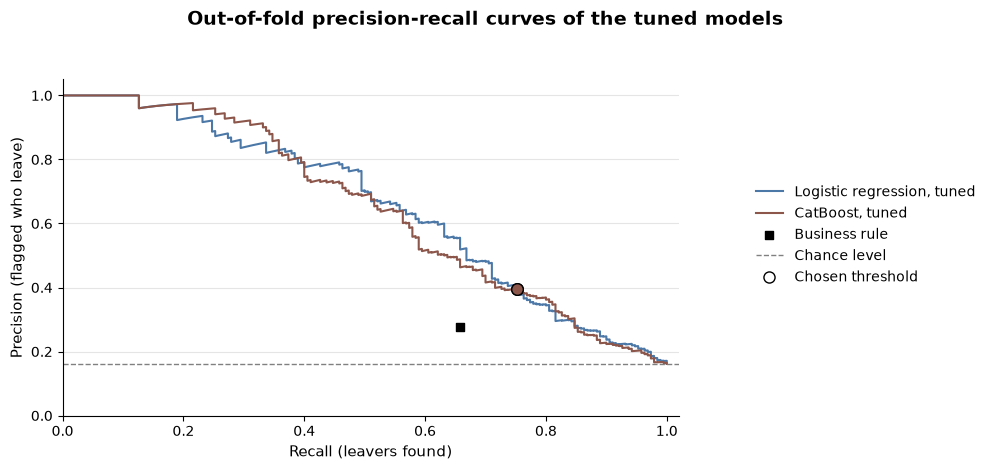

In [121]:
plot_oof_curves(
    "Out-of-fold precision-recall curves of the tuned models",
    tuned_thresholds,
    tuned_probabilities,
    TUNED_COLORS,
)

We store the tuned CatBoost parameters and its threshold, which the final evaluation will use.

In [122]:
FINAL = {
    "params": {
        key.removeprefix("model__"): value.item()
        if isinstance(value, np.generic)
        else value
        for key, value in catboost_search.best_params_.items()
    },
    "threshold": float(tuned_thresholds.loc["CatBoost, tuned", "Threshold"]),
}
print(FINAL)

{'params': {'auto_class_weights': 'SqrtBalanced', 'depth': 4, 'iterations': 469, 'l2_leaf_reg': 11.865032251194263, 'learning_rate': 0.030362694519014993}, 'threshold': 0.2192215367748833}


#### Decision

We freeze the tuned CatBoost and its threshold in FINAL, with the minimum recall of 0.75 set before opening the test set.

## 14. Final evaluation on the test set

We fit the final CatBoost on the full training set with the parameters stored in FINAL, and keep the tuned logistic regression, also fitted on the full training set, as the benchmark. The test set is scored once, at the thresholds chosen in cross-validation.

In [123]:
final_catboost = build_pipeline(
    CatBoostClassifier(
        **FINAL["params"],
        verbose=0,
        random_state=RANDOM_STATE,
        allow_writing_files=False,
    ),
    "tree",
).fit(X_train, y_train)
FINAL_MODELS = {
    "CatBoost, tuned": final_catboost,
    "Logistic regression, tuned": logistic_search.best_estimator_,
}
test_probabilities = {
    name: model.predict_proba(X_test)[:, 1] for name, model in FINAL_MODELS.items()
}

We compare each model on the test set with its out-of-fold values at the same threshold, to see how far the cross-validation figures hold on unseen employees.

In [124]:
def final_scores(y_part, flagged, scores=None):
    """Return the PR-AUC, precision, recall and number of flagged employees of one model on one set."""
    return {
        "PR-AUC": np.nan if scores is None else average_precision_score(y_part, scores),
        "Precision": precision_score(y_part, flagged),
        "Recall": recall_score(y_part, flagged),
        "Flagged employees": int(flagged.sum()),
    }


sets = {
    "Out-of-fold": (y_train, tuned_probabilities),
    "Test": (y_test, test_probabilities),
}
rows = {}
for name in FINAL_MODELS:
    threshold = tuned_thresholds.loc[name, "Threshold"]
    rows[name] = {
        (metric, part): value
        for part, (y_part, scores) in sets.items()
        for metric, value in final_scores(
            y_part, scores[name] >= threshold, scores[name]
        ).items()
    }
rows[RULE_NAME] = {
    (metric, part): value
    for part, (X_part, y_part) in {
        "Out-of-fold": (X_train, y_train),
        "Test": (X_test, y_test),
    }.items()
    for metric, value in final_scores(y_part, apply_business_rule(X_part) == 1).items()
}
metrics_order = ["PR-AUC", "Precision", "Recall", "Flagged employees"]
final_table = pd.DataFrame.from_dict(rows, orient="index")
final_table.columns = pd.MultiIndex.from_tuples(final_table.columns)
final_table = final_table[pd.MultiIndex.from_product([metrics_order, sets])]
display(final_table.round(2))
print(
    f"Out-of-fold set: {len(y_train):,} employees, test set: {len(y_test):,} employees"
)

PR-AUC         Precision            Recall  \
                           Out-of-fold  Test Out-of-fold  Test Out-of-fold   
CatBoost, tuned                   0.65  0.50        0.39  0.35        0.75   
Logistic regression, tuned        0.66  0.55        0.39  0.41        0.75   
Business rule                      NaN   NaN        0.28  0.38        0.66   

                                 Flagged employees       
                            Test       Out-of-fold Test  
CatBoost, tuned             0.74               363  100  
Logistic regression, tuned  0.68               363   79  
Business rule               0.77               450   96

Out-of-fold set: 1,176 employees, test set: 294 employees


On the test set, the final CatBoost finds almost the same share of leavers as the business rule, with a recall of 0.74 against 0.77, and flags almost the same number of employees, 100 against 96. Its precision is 0.35 against 0.38, so the model does not beat the rule there, while it did in cross-validation with 0.39 against 0.28.

The test set holds only 47 leavers, so one leaver moves the recall by about 2 points, and the cross-validation on 1,176 employees is the more reliable estimate.

Both models lose PR-AUC on the test set, from 0.65 to 0.50 for CatBoost and from 0.66 to 0.55 for the logistic regression, and for CatBoost part of the drop comes from the optimistic best trial.

We plot the confusion matrix of the final CatBoost on the test set at its threshold, to see how many leavers it finds and how many stayers it flags.

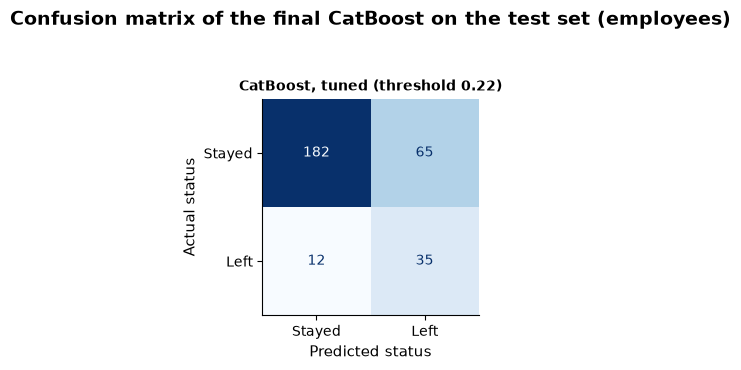

In [133]:
final_threshold = FINAL["threshold"]
fig, axes = make_grid(1, panel_height=4, n_cols=1, width=5)
ax = axes[0]
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_probabilities["CatBoost, tuned"] >= final_threshold,
    display_labels=["Stayed", "Left"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"CatBoost, tuned (threshold {final_threshold:.2f})", fontsize=10)
ax.set_xlabel("Predicted status")
ax.set_ylabel("Actual status")
ax.grid(False)
fig.suptitle(
    "Confusion matrix of the final CatBoost on the test set (employees)",
    fontsize=14,
    fontweight="bold",
)
plt.show()

#### Decision

The model is frozen and stays as it is, since the test set is scored once and is not used to change it.

## 15. Global feature importance

We explain the final CatBoost on the training set with three methods: its native importance, the permutation importance of the full pipeline and the SHAP values. We compare the three rankings on the same columns. In the SHAP plots, red means a high value of the column in the beeswarm and a push toward leaving in the waterfall plots.

We compute the native importance of CatBoost on the encoded columns, and the permutation importance of the full pipeline, which shuffles each original column ten times and measures the drop in PR-AUC.

In [134]:
preprocessing = final_catboost.named_steps["preprocessing"]
catboost_model = final_catboost.named_steps["model"]
GROUPED_COLUMNS = [*NOMINAL_COLUMNS, *BINARY_COLUMNS]


def encode(X_part):
    """Return the encoded columns that the CatBoost model receives, with their names."""
    values = preprocessing.transform(X_part)
    return pd.DataFrame(
        values.toarray() if hasattr(values, "toarray") else values,
        columns=preprocessing.get_feature_names_out(),
        index=X_part.index,
    )


def original_column(encoded_name):
    """Return the column of X_train that an encoded column comes from."""
    for column in GROUPED_COLUMNS:
        if encoded_name.startswith(f"{column}_"):
            return column
    return encoded_name


X_encoded = encode(X_train)
encoded_to_original = pd.Series(
    {name: original_column(name) for name in X_encoded.columns}
)
assert set(encoded_to_original.to_numpy()) == set(X_train.columns)


# SHAP splits each label on " = " to show the value, so these labels do not carry it
SHAP_LABELS = {"heures_supplementaires": "Works overtime", "genre": "Gender (male)"}


def display_name(encoded_name):
    """Return the readable label of an encoded column, followed by its category for a one-hot column."""
    column = original_column(encoded_name)
    label = SHAP_LABELS.get(column, COLUMN_LABELS.get(column, column))
    if column in NOMINAL_COLUMNS:
        return f"{label}: {encoded_name[len(column) + 1 :]}"
    return label


DISPLAY_NAMES = [display_name(name) for name in X_encoded.columns]
assert len(set(DISPLAY_NAMES)) == len(DISPLAY_NAMES)
assert not any(" = " in name for name in DISPLAY_NAMES)


def to_original(importance):
    """Sum the importance of the encoded columns back to their original column."""
    return importance.groupby(encoded_to_original).sum()


native_importance = to_original(
    pd.Series(catboost_model.get_feature_importance(), index=X_encoded.columns)
)
permutation = permutation_importance(
    final_catboost,
    X_train,
    y_train,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
permutation_importances = pd.Series(permutation.importances_mean, index=X_train.columns)

We compute the SHAP values of the final CatBoost with a tree explainer on the encoded training set, in log-odds of leaving.

In [135]:
explainer = shap.TreeExplainer(catboost_model)
shap_values = explainer(X_encoded.set_axis(DISPLAY_NAMES, axis=1))
shap_encoded_importance = pd.Series(
    np.abs(shap_values.values).mean(axis=0), index=X_encoded.columns
).sort_values(ascending=False)
shap_importance = to_original(shap_encoded_importance)

We compare the three methods on the union of their top 10 columns, as a share of each total importance, with the one-hot columns summed back to their original column. The error bars show the standard deviation over the ten permutation repeats.

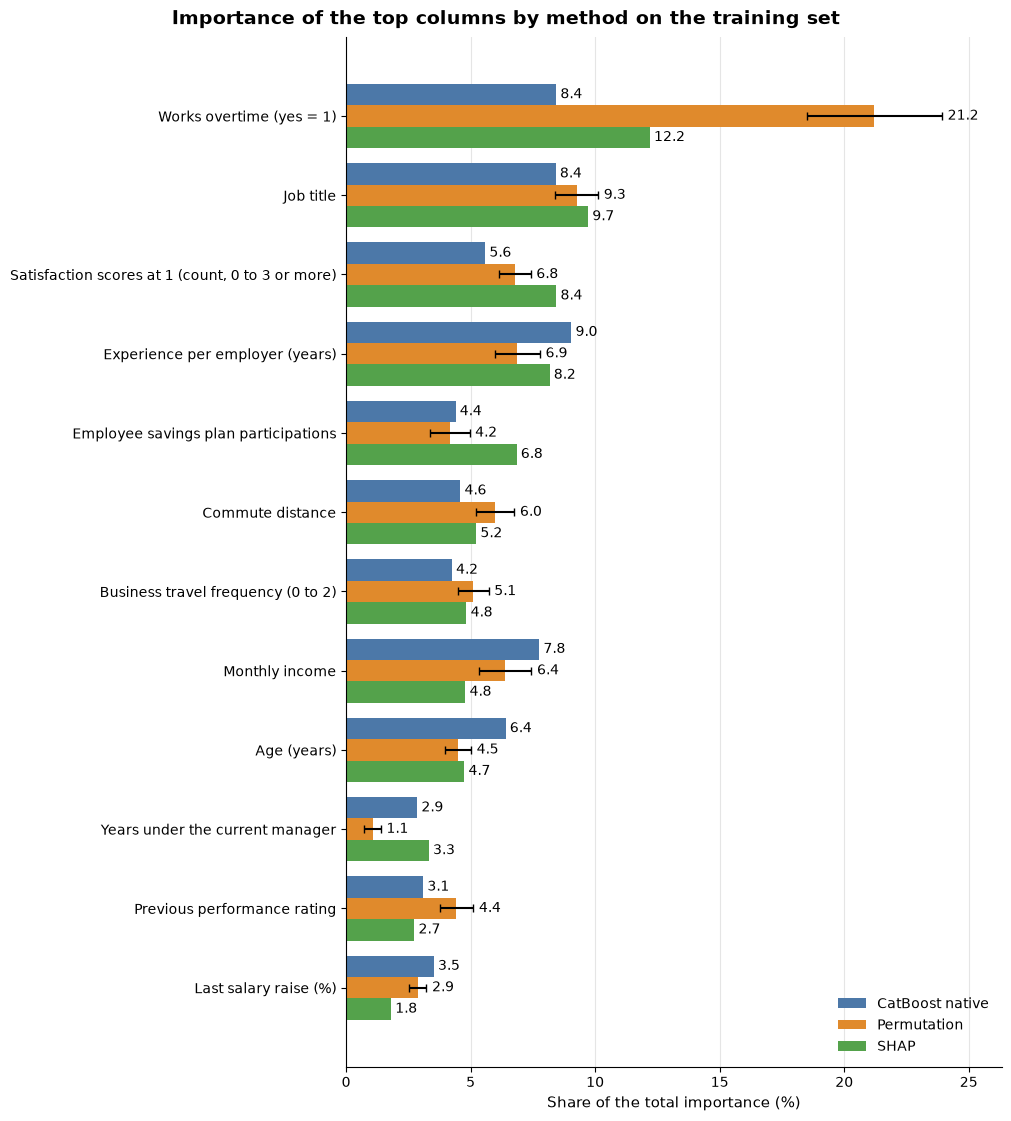

In [136]:
importance_shares = pd.DataFrame(
    {
        "CatBoost native": native_importance,
        "Permutation": permutation_importances,
        "SHAP": shap_importance,
    }
)
importance_shares = importance_shares / importance_shares.sum() * 100
top_columns = set().union(
    *(importance_shares[method].nlargest(10).index for method in importance_shares)
)
importance_shares = importance_shares.loc[
    importance_shares.index.isin(top_columns)
].sort_values("SHAP", ascending=False)
permutation_error = pd.Series(
    permutation.importances_std / permutation_importances.sum() * 100,
    index=X_train.columns,
)

method_colors = {
    "CatBoost native": "#4c78a8",
    "Permutation": "#e08a2c",
    "SHAP": "#54a24b",
}
bar_height = 0.27
positions = np.arange(len(importance_shares))
fig, ax = plt.subplots(
    figsize=(10, 0.8 * len(importance_shares) + 1.5), layout="constrained"
)
for offset, method in zip((-1, 0, 1), importance_shares.columns):
    values = importance_shares[method]
    y = positions + offset * bar_height
    if method == "Permutation":
        error = permutation_error[importance_shares.index]
        ax.barh(
            y,
            values,
            height=bar_height,
            color=method_colors[method],
            label=method,
            xerr=error,
            capsize=3,
        )
        # The value goes after the end of the error bar, which is wider than the bar
        for y_i, value, error_i in zip(y, values, error):
            ax.annotate(
                f"{value:.1f}",
                (max(value, 0) + error_i, y_i),
                xytext=(4, 0),
                textcoords="offset points",
                va="center",
            )
    else:
        bars = ax.barh(
            y, values, height=bar_height, color=method_colors[method], label=method
        )
        ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_yticks(
    positions,
    labels=[COLUMN_LABELS.get(col, col) for col in importance_shares.index],
)
ax.invert_yaxis()
ax.margins(x=0.1)
ax.set_xlabel("Share of the total importance (%)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.suptitle(
    "Importance of the top columns by method on the training set",
    fontsize=14,
    fontweight="bold",
)
plt.show()

The three methods put overtime, job title and experience per employer in their top four, and the satisfaction scores at 1 in their top six.

The native importance gives more weight to continuous columns, with the monthly income at 7.8 percent against 4.8 for SHAP and the age at 6.4 against 4.7, a known bias of split-based importance.

We draw the beeswarm plot of the SHAP values.

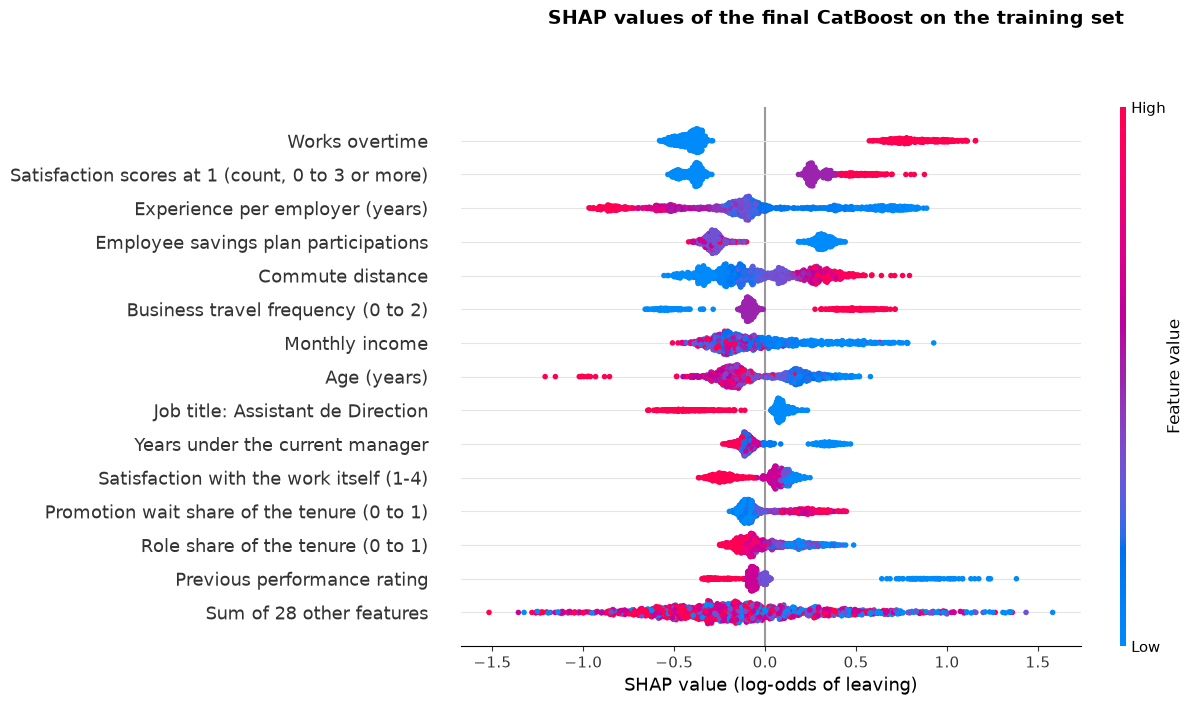

In [137]:
shap.plots.beeswarm(shap_values, max_display=15, show=False, plot_size=(10, 7))
fig = plt.gcf()
fig.axes[0].set_xlabel("SHAP value (log-odds of leaving)")
fig.suptitle(
    "SHAP values of the final CatBoost on the training set",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.show()

Overtime, more satisfaction scores at 1, a longer commute and more frequent business travel push toward leaving, and their opposite values push toward staying.

Fewer years of experience per employer, fewer savings plan participations, a younger age, a lower monthly income and a low previous performance rating also push toward leaving. The income colors are more mixed than the others.

We plot the SHAP value of the top four columns against their values, each one colored by the column that interacts most with it.

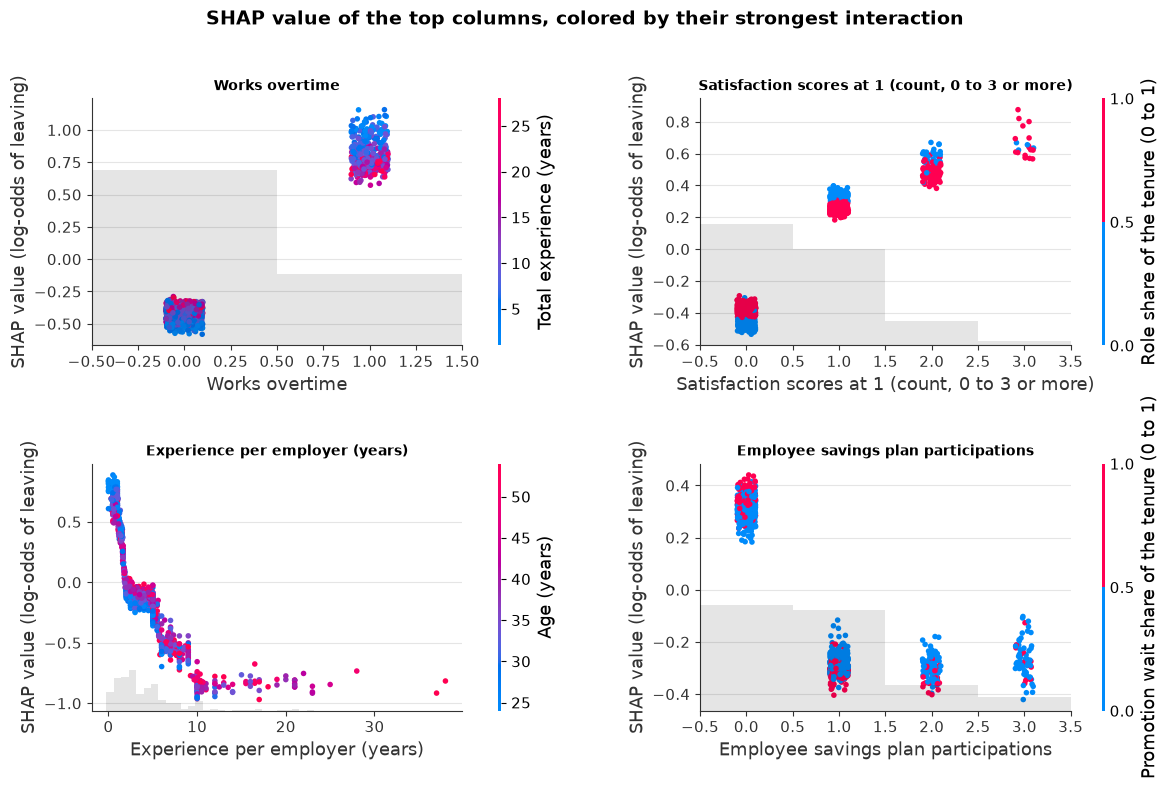

In [138]:
# A one-hot column has only two values, so the dependence plots use the other columns
scatter_features = [
    name
    for name in shap_encoded_importance.index
    if original_column(name) not in NOMINAL_COLUMNS
][:4]

fig, axes = make_grid(len(scatter_features), panel_height=4, n_cols=2, width=12)
for ax, name in zip(axes, scatter_features):
    label = display_name(name)
    shap.plots.scatter(shap_values[:, label], color=shap_values, ax=ax, show=False)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel(label)
    ax.set_ylabel("SHAP value (log-odds of leaving)")
fig.suptitle(
    "SHAP value of the top columns, colored by their strongest interaction",
    fontsize=14,
    fontweight="bold",
)
plt.show()

The effects are step-like for the overtime, the satisfaction scores at 1 and the savings plan, and drop sharply before flattening for the experience per employer. The colors stay mostly mixed inside each step, which suggests that the model uses few interactions.

We group the 27 columns into seven business groups, sum the SHAP values of each group for each employee and take the mean absolute value, so that opposite effects inside a group cancel out for an employee.

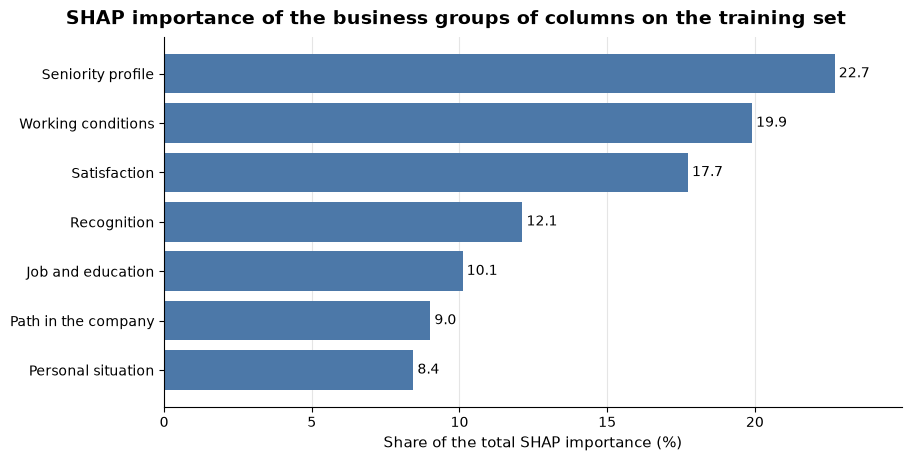

In [142]:
COLUMN_GROUPS = {
    "Seniority profile": [
        "age",
        "annees_experience_totale",
        "years_per_employer",
        "nombre_experiences_precedentes",
        "revenu_mensuel",
    ],
    "Path in the company": [
        "annees_dans_l_entreprise",
        "annees_sous_responsable_actuel",
        "career_share_in_company",
        "role_share_of_tenure",
        "promotion_wait_share",
    ],
    "Satisfaction": [
        "satisfaction_employee_environnement",
        "satisfaction_employee_nature_travail",
        "satisfaction_employee_equipe",
        "satisfaction_employee_equilibre_pro_perso",
        "satisfaction_lows",
    ],
    "Working conditions": ["heures_supplementaires", "frequence_deplacement"],
    "Recognition": [
        "augmentation_salaire_precedente",
        "note_evaluation_precedente",
        "nombre_participation_pee",
        "nb_formations_suivies",
    ],
    "Job and education": ["poste", "domaine_etude", "niveau_education"],
    "Personal situation": ["genre", "statut_marital", "distance_domicile_travail"],
}
group_of = {
    column: group for group, columns in COLUMN_GROUPS.items() for column in columns
}
assert len(group_of) == sum(len(columns) for columns in COLUMN_GROUPS.values())
assert set(group_of) == set(X_train.columns)

group_shap = (
    pd.DataFrame(shap_values.values, columns=X_encoded.columns)
    .T.groupby(encoded_to_original.map(group_of))
    .sum()
    .T
)
group_importance = group_shap.abs().mean()
group_share = (group_importance / group_importance.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
bars = ax.barh(group_share.index, group_share, color=RATE_BAR_COLOR)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.margins(x=0.1)
ax.set_xlabel("Share of the total SHAP importance (%)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.suptitle(
    "SHAP importance of the business groups of columns on the training set",
    fontsize=14,
    fontweight="bold",
)
plt.show()

The seniority profile weighs the most with 22.7 percent, followed by the working conditions at 19.9 and the satisfaction at 17.7. The three groups the company can act on, the working conditions, the satisfaction and the recognition, make 49.7 percent, about half of the importance. The path in the company weighs little, with 9.0 percent.

The top of the ranking depends on where the monthly income sits, since the seniority profile holds it. The three blocks around 18 to 23 percent and the half-and-half split between the groups the company can act on and the others hold either way.

## 16. Local feature importance

We explain four employees of the test set at the final threshold: a typical leaver found, the false alarm with the highest probability, the missed leaver with the lowest probability and a typical stayer. For the typical cases, we take the employee closest to the median probability of the group.

In [139]:
test_scores = test_probabilities["CatBoost, tuned"]
test_flagged = test_scores >= FINAL["threshold"]
test_leaver = y_test.to_numpy() == 1


def pick_employee(mask, how):
    """Return the position in the test set of the employee with the highest, lowest or median probability among mask."""
    positions = np.flatnonzero(mask)
    scores = test_scores[positions]
    if how == "max":
        return int(positions[np.argmax(scores)])
    if how == "min":
        return int(positions[np.argmin(scores)])
    return int(positions[np.argmin(np.abs(scores - np.median(scores)))])


cases = {
    "Typical leaver found": pick_employee(test_flagged & test_leaver, "median"),
    "False alarm with the highest probability": pick_employee(
        test_flagged & ~test_leaver, "max"
    ),
    "Missed leaver with the lowest probability": pick_employee(
        ~test_flagged & test_leaver, "min"
    ),
    "Typical stayer": pick_employee(~test_flagged & ~test_leaver, "median"),
}
display(
    pd.DataFrame(
        {
            "Employee": [X_test.index[position] for position in cases.values()],
            "Predicted probability": [
                test_scores[position] for position in cases.values()
            ],
            "Flagged": [
                "Yes" if test_flagged[position] else "No" for position in cases.values()
            ],
            "Actual status": [
                "Left" if test_leaver[position] else "Stayed"
                for position in cases.values()
            ],
        },
        index=pd.Index(list(cases), name="Case"),
    ).round(2)
)

,Employee,Predicted probability,Flagged,Actual status
Case,,,,
Typical leaver found,923,0.47,Yes,Left
False alarm with the highest probability,1974,0.83,Yes,Stayed
Missed leaver with the lowest probability,1572,0.01,No,Left
Typical stayer,178,0.08,No,Stayed


We draw one waterfall plot per employee, which starts from the average output of the model and adds the contribution of each column, in log-odds, up to the score of the employee.

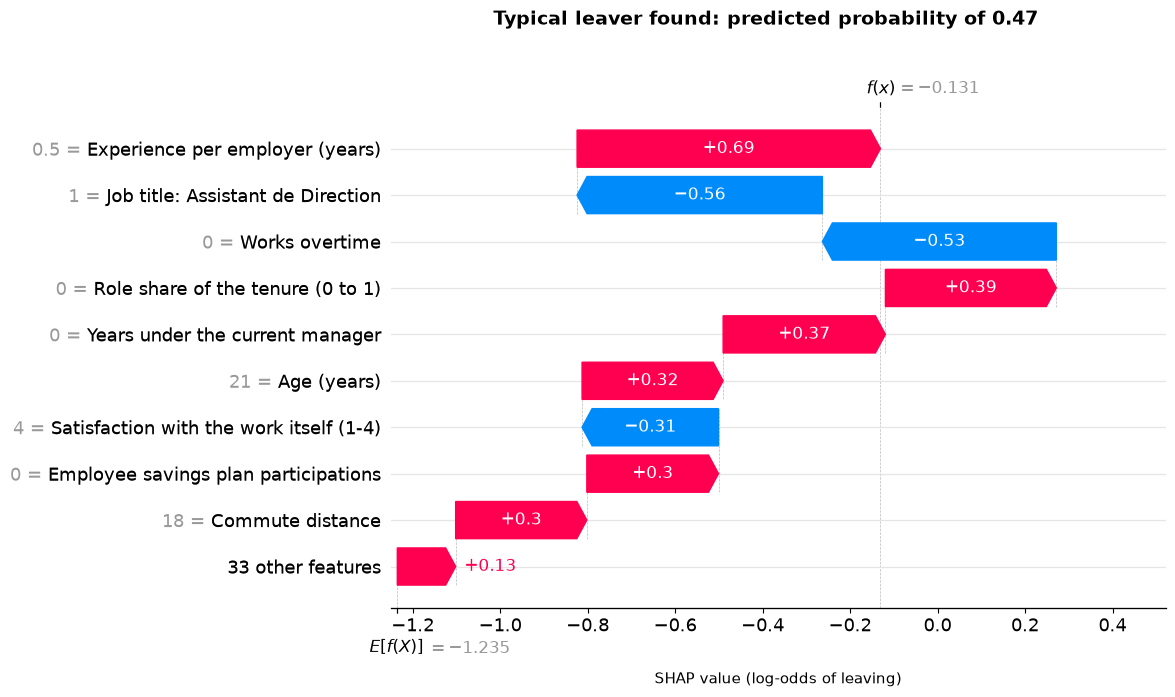

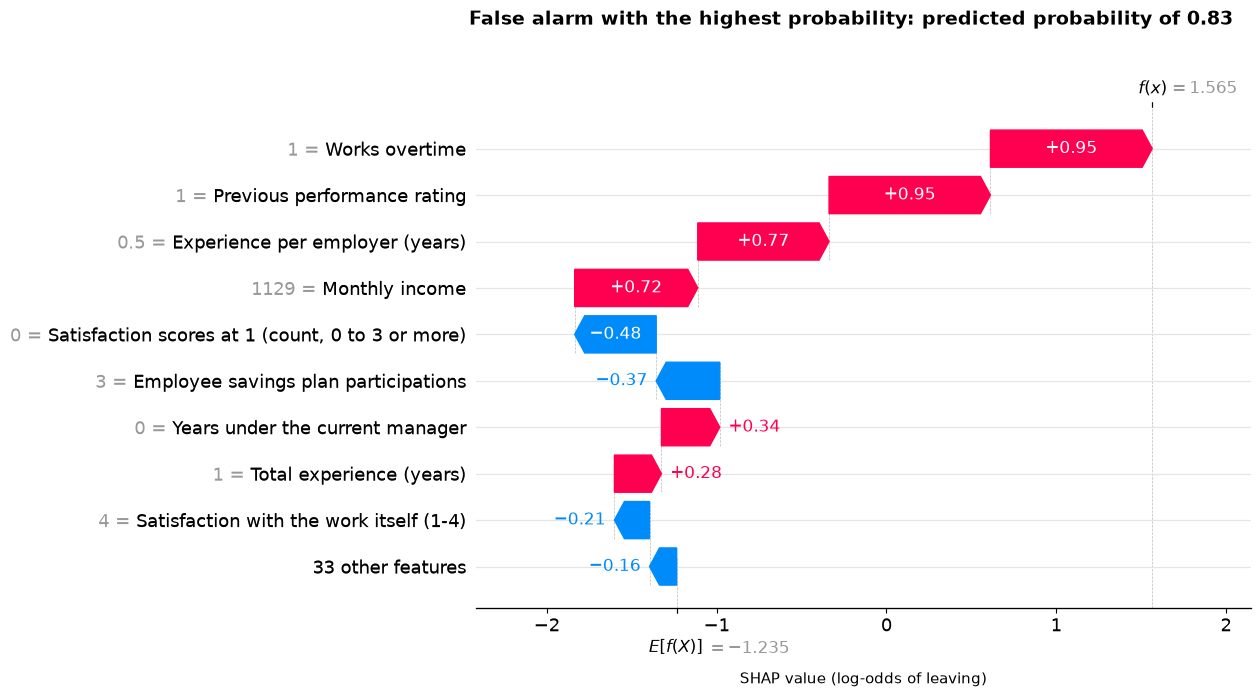

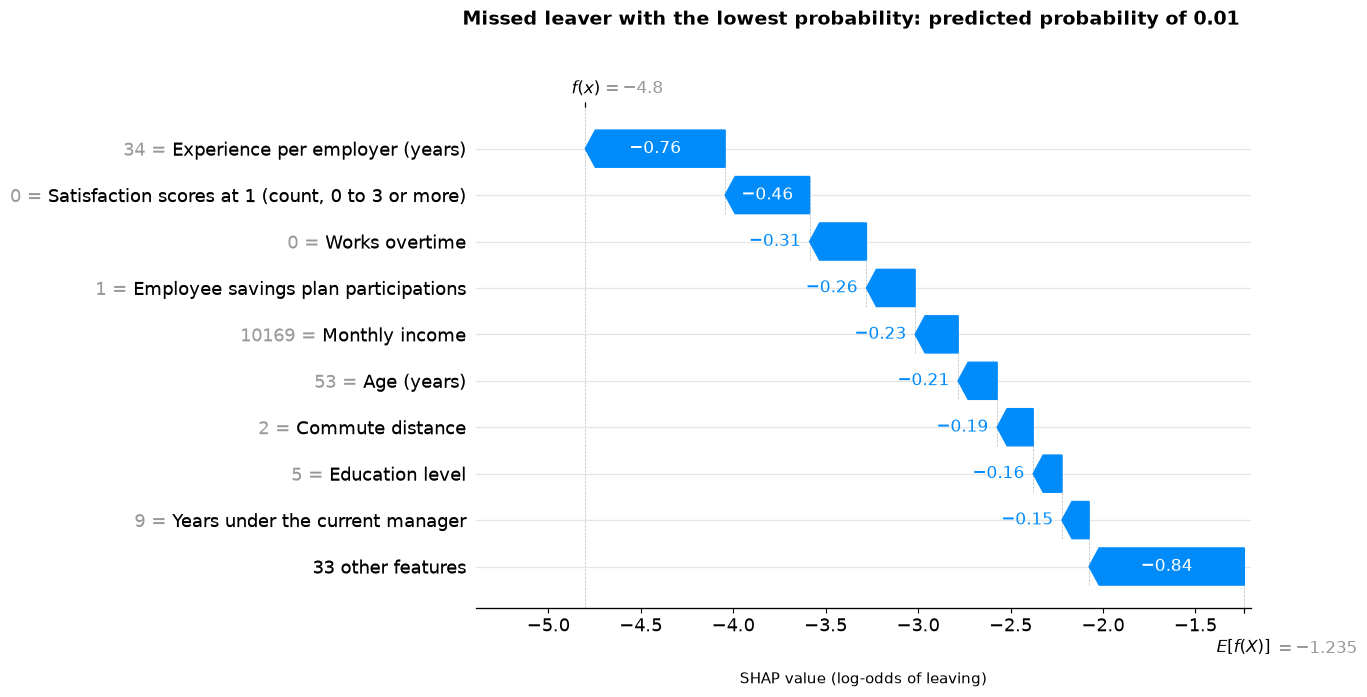

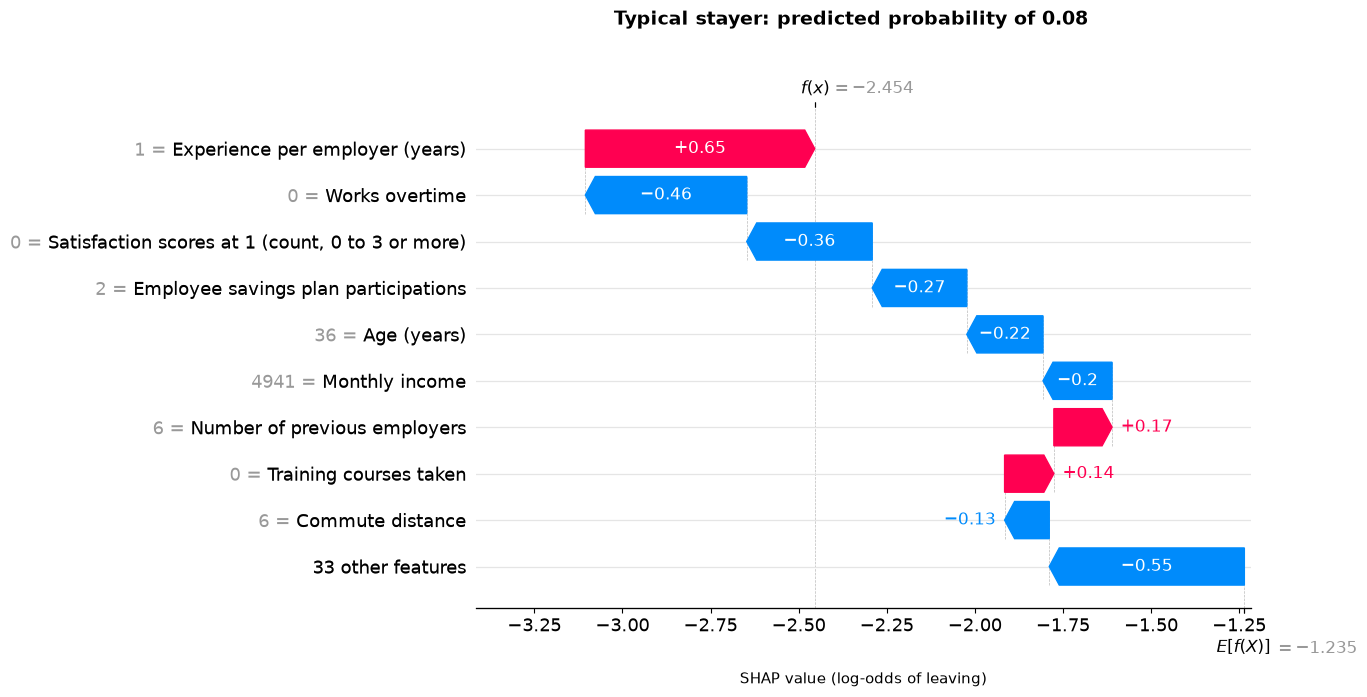

In [140]:
shap_test = explainer(encode(X_test).set_axis(DISPLAY_NAMES, axis=1))
for case, position in cases.items():
    shap.plots.waterfall(shap_test[position], max_display=10, show=False)
    fig = plt.gcf()
    fig.set_size_inches(10, fig.get_figheight())
    # The label padding keeps the axis label below the E[f(X)] label that SHAP draws under the axis
    fig.axes[0].set_xlabel("SHAP value (log-odds of leaving)", labelpad=26)
    fig.suptitle(
        f"{case}: predicted probability of {test_scores[position]:.2f}",
        fontsize=14,
        fontweight="bold",
        y=1.03,
    )
    plt.show()

The typical leaver found is a junior employee, aged 21 with half a year of experience per employer, who works no overtime and has only one satisfaction score at 1, so the business rule does not flag this employee at all, while the model does.

The strongest false alarm combines overtime, a previous rating of 1, half a year of experience per employer and a monthly income of 1,129, which are the main risk signals of a leaver, and still stayed.

The missed leaver has a predicted probability of 0.01, and all ten largest contributions push toward staying, so the model finds no risk signal in the data of this employee. The target also covers every departure, not only resignations.

The typical stayer has no overtime, no satisfaction score at 1 and two savings plan participations, which all push toward staying, and only the single year of experience per employer pushes toward leaving.

## 17. Conclusion

### What the model is worth

In cross-validation, the final CatBoost beats the business rule at the minimum recall of 0.75, with a precision of 0.39 against 0.28. On the test set it ties with the rule, since its recall of 0.74 against 0.77 is one employee apart among 47 leavers.

The logistic regression does as well as or better than CatBoost, so the signal is mostly additive and the data limit what any model can reach.

The model still adds three things to the rule: a ranking of the employees, a threshold we can adjust and an explanation for each employee. The typical leaver found in section 16 shows it, since the rule does not flag this employee at all.

### What the model links to leaving

The three groups the company can act on, the working conditions, the satisfaction and the recognition, make 49.7 percent, about half, and the profile groups make the other half.

The model links four columns that the company can act on to leaving: working overtime, a higher count of satisfaction scores at 1, fewer savings plan participations and more frequent business travel.

It also links a profile to leaving, made of the job role (the job title column), fewer years of experience per employer, a longer commute, a younger age and a lower monthly income.

These are associations learned by the model, not proven causes.

### Limitations

- The test set holds only 47 leavers, so one leaver moves the recall by about 2 points.
- The target covers every departure, not only resignations.
- The business rule was built on all the employees, which can only favor it over the model.
- The global importances are computed on the training set, so they describe what the model learned there.